# Victorian Waste Forecasting Models
**Group 2 (P000179DSUG) | Deloitte Australia**

| Part | Role | Model | Source | History | Horizon |
|---|---|---|---|---|---|
| **Part 1** | **Primary** | ARIMA / Log-ARIMA / ETS / ARIMAX — 10 categories | `cleaned_vlgas.csv` (79 councils) | 23 years (2001–2024) | 2030 |
| **Part 2** | **LGA Breakdown** | ARIMA — per-council diversion rate | `cleaned_vlgas.csv` | 23 years | 2030 |
| **Part 3** | **Supplementary** | ARIMA — Melbourne case study | `waste-collected-per-month.xlsx` | 10 years (2010–2019) | 2030 |

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
%matplotlib inline

ROOT       = Path(".")
GOLD_DIR   = ROOT / "Dataset" / "Gold"
CHARTS_DIR = ROOT / "outputs" / "charts"

# Part-specific export directories
STATEWIDE_DIR = GOLD_DIR / "statewide"
MELB_DIR      = GOLD_DIR / "city_of_melbourne"
LGA_DIR       = GOLD_DIR / "statewide" / "lga"

for _d in [GOLD_DIR, CHARTS_DIR, STATEWIDE_DIR, MELB_DIR, LGA_DIR]:
    _d.mkdir(parents=True, exist_ok=True)

HIST_COLOR       = "#2c3e50"
FC_COLOR         = "#2980b9"
CI_COLOR         = "#85c1e9"
ALPHA            = 0.05
TARGET_YEAR      = 2030
DIVERSION_TARGET = 0.80

print("Directories ready.")
print(f"  STATEWIDE_DIR : {STATEWIDE_DIR}")
print(f"  MELB_DIR      : {MELB_DIR}")
print(f"  LGA_DIR       : {LGA_DIR}")

Directories ready.
  STATEWIDE_DIR : Dataset\Gold\statewide
  MELB_DIR      : Dataset\Gold\city_of_melbourne
  LGA_DIR       : Dataset\Gold\statewide\lga


## Shared Helpers

In [2]:
def mape(actual, predicted) -> float:
    actual, predicted = np.array(actual, dtype=float), np.array(predicted, dtype=float)
    mask = actual != 0
    return float(np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100)


def evaluate(actual, predicted, label: str) -> dict:
    mae_v  = mean_absolute_error(actual, predicted)
    rmse_v = np.sqrt(mean_squared_error(actual, predicted))
    mape_v = mape(actual, predicted)
    print(f"    MAE  = {mae_v:.4f}")
    print(f"    RMSE = {rmse_v:.4f}")
    print(f"    MAPE = {mape_v:.2f}%")
    return {"series": label,
            "MAE":      round(mae_v,  4),
            "RMSE":     round(rmse_v, 4),
            "MAPE_pct": round(mape_v, 2)}


def ts_cross_validate(series: np.ndarray, order: tuple,
                      seasonal_order: tuple = (0, 0, 0, 0),
                      n_splits: int = 3, test_size: int = 1) -> dict:
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)
    maes, rmses = [], []
    for train_idx, test_idx in tscv.split(series):
        train, test = series[train_idx], series[test_idx]
        p = max(order[0], seasonal_order[0]) if seasonal_order else order[0]
        if len(train) < p + 5:
            continue
        try:
            fit  = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                           enforce_stationarity=False, enforce_invertibility=False
                           ).fit(disp=False)
            pred = fit.forecast(steps=len(test))
            maes.append(mean_absolute_error(test, pred))
            rmses.append(np.sqrt(mean_squared_error(test, pred)))
        except Exception:
            continue
    return {"cv_mae_mean":  round(np.mean(maes),  4) if maes  else np.nan,
            "cv_rmse_mean": round(np.mean(rmses), 4) if rmses else np.nan,
            "cv_folds":     len(maes)}


def fit_arima(series: pd.Series, label: str, forecast_steps: int,
              test_size: int = 3, trend: str = 'c',
              log_transform: bool = False, max_d: int = 2,
              ci_alpha: float = None, forecast_cap: float = None) -> tuple:
    # max_d: caps differencing order; use 1 to prevent aggressive I(2) on short/volatile series
    # ci_alpha: CI level override (None -> use global ALPHA=0.05); set 0.20 for 80% CI
    # forecast_cap: hard upper bound on back-transformed point forecast (None = no cap)
    """Fit ARIMA (with optional log-transform) and return (DataFrame, metrics)."""
    raw_values = series.dropna().values.astype(float)
    index      = series.dropna().index
    n          = len(raw_values)

    if log_transform:
        # Shift if any values <= 0 before log
        shift = max(0, -raw_values.min() + 1e-6)
        values = np.log(raw_values + shift)
    else:
        shift  = 0.0
        values = raw_values

    _ci_alpha = ci_alpha if ci_alpha is not None else ALPHA

    effective_test = min(test_size, max(1, n - 4))
    if effective_test != test_size:
        print(f"    [short series] test_size {test_size} -> {effective_test}")
        test_size = effective_test

    train_vals, test_vals = values[:-test_size], values[-test_size:]
    reliability = "high" if n >= 15 else "medium" if n >= 10 else "low_short_history"

    tag = " [log]" if log_transform else ""
    print(f"\n  [{label}]{tag}")
    print(f"    train={len(train_vals)}  test={test_size}  horizon={forecast_steps}  "
          f"reliability={reliability} (n={n})")

    auto = pm.auto_arima(train_vals, seasonal=False, m=1, stepwise=True,
                         information_criterion="aic", suppress_warnings=True,
                         error_action="ignore", with_intercept=True, trend=trend,
                         max_p=3, max_q=3, max_d=max_d, n_fits=20)
    order = auto.order
    print(f"    Best order: ARIMA{order}  AIC={auto.aic():.2f}")

    sarimax_trend = trend if (order[1] > 0 or order[0] == 0) else 'n'

    train_fit = SARIMAX(train_vals, order=order, seasonal_order=(0,0,0,0),
                        trend=sarimax_trend,
                        enforce_stationarity=False, enforce_invertibility=False
                        ).fit(disp=False)

    test_pred_raw = train_fit.forecast(steps=test_size)
    if log_transform:
        test_pred_orig = np.clip(np.exp(test_pred_raw) - shift, 0, None)
        test_vals_orig = raw_values[-test_size:]
    else:
        test_pred_orig = test_pred_raw
        test_vals_orig = test_vals

    print("    Test set evaluation:")
    metrics = evaluate(test_vals_orig, test_pred_orig, label)
    metrics.update({"order": str(order), "AIC": round(auto.aic(), 2),
                    "test_size": test_size, "reliability": reliability,
                    "n_years_history": n,
                    "log_transform": log_transform,
                    "ci_alpha_used": _ci_alpha})

    cv = ts_cross_validate(train_vals, order, n_splits=3, test_size=1)
    metrics.update(cv)
    print(f"    CV MAE={cv['cv_mae_mean']}  CV RMSE={cv['cv_rmse_mean']}  ({cv['cv_folds']} folds)")

    full_fit  = SARIMAX(values, order=order, seasonal_order=(0,0,0,0),
                        trend=sarimax_trend,
                        enforce_stationarity=False, enforce_invertibility=False
                        ).fit(disp=False)
    fc_res    = full_fit.get_forecast(steps=forecast_steps)
    fc_mean_t = np.array(fc_res.predicted_mean).flatten()
    fc_ci     = fc_res.conf_int(alpha=_ci_alpha)
    fc_ci_lo_t    = np.array(fc_ci)[:, 0]
    fc_ci_hi_t    = np.array(fc_ci)[:, 1]
    fc_ci_50      = fc_res.conf_int(alpha=0.50)
    fc_ci_lo_50_t = np.array(fc_ci_50)[:, 0]
    fc_ci_hi_50_t = np.array(fc_ci_50)[:, 1]

    if log_transform:
        fc_mean      = np.clip(np.exp(fc_mean_t)      - shift, 0, None)
        fc_ci_lo     = np.clip(np.exp(fc_ci_lo_t)     - shift, 0, None)
        fc_ci_hi     = np.clip(np.exp(fc_ci_hi_t)     - shift, 0, None)
        fc_ci_lo_50  = np.clip(np.exp(fc_ci_lo_50_t)  - shift, 0, None)
        fc_ci_hi_50  = np.clip(np.exp(fc_ci_hi_50_t)  - shift, 0, None)
    else:
        fc_mean      = fc_mean_t
        fc_ci_lo     = fc_ci_lo_t
        fc_ci_hi     = fc_ci_hi_t
        fc_ci_lo_50  = fc_ci_lo_50_t
        fc_ci_hi_50  = fc_ci_hi_50_t

    # Apply hard cap to point forecast (e.g. FOGO physical ceiling)
    if forecast_cap is not None:
        fc_idx_tmp = np.arange(index[-1] + 1, index[-1] + 1 + forecast_steps)
        cap_mask   = fc_mean > forecast_cap
        if cap_mask.any():
            for _yr, _raw in zip(fc_idx_tmp[cap_mask], fc_mean[cap_mask]):
                print(f"    [CAP] {_yr}: {_raw:.1f} kt -> capped at {forecast_cap:.1f} kt")
        fc_mean = np.clip(fc_mean, None, forecast_cap)

    burn_in   = 2
    in_sample = full_fit.get_prediction(start=burn_in)
    hist_mean_t = np.array(in_sample.predicted_mean).flatten()
    hist_ci      = in_sample.conf_int(alpha=_ci_alpha)
    hist_lo_t    = np.array(hist_ci)[:, 0]
    hist_hi_t    = np.array(hist_ci)[:, 1]
    hist_ci_50   = in_sample.conf_int(alpha=0.50)
    hist_lo_50_t = np.array(hist_ci_50)[:, 0]
    hist_hi_50_t = np.array(hist_ci_50)[:, 1]

    if log_transform:
        hist_mean_vals  = np.clip(np.exp(hist_mean_t)  - shift, 0, None)
        hist_lo_vals    = np.clip(np.exp(hist_lo_t)    - shift, 0, None)
        hist_hi_vals    = np.clip(np.exp(hist_hi_t)    - shift, 0, None)
        hist_lo_50_vals = np.clip(np.exp(hist_lo_50_t) - shift, 0, None)
        hist_hi_50_vals = np.clip(np.exp(hist_hi_50_t) - shift, 0, None)
    else:
        hist_mean_vals  = hist_mean_t
        hist_lo_vals    = hist_lo_t
        hist_hi_vals    = hist_hi_t
        hist_lo_50_vals = hist_lo_50_t
        hist_hi_50_vals = hist_hi_50_t

    fitted_full            = np.full(n, np.nan)
    lo_full                = np.full(n, np.nan)
    hi_full                = np.full(n, np.nan)
    lo_full_50             = np.full(n, np.nan)
    hi_full_50             = np.full(n, np.nan)
    fitted_full[burn_in:]  = hist_mean_vals
    lo_full[burn_in:]      = hist_lo_vals
    hi_full[burn_in:]      = hist_hi_vals
    lo_full_50[burn_in:]   = hist_lo_50_vals
    hi_full_50[burn_in:]   = hist_hi_50_vals

    hist_df = pd.DataFrame({"index": index, "actual": raw_values, "fitted": fitted_full,
                             "lower_ci": lo_full, "upper_ci": hi_full,
                             "lower_ci_50": lo_full_50, "upper_ci_50": hi_full_50,
                             "is_forecast": False, "series": label, "reliability": reliability})
    fc_idx  = np.arange(index[-1] + 1, index[-1] + 1 + forecast_steps)
    fc_df   = pd.DataFrame({"index": fc_idx, "actual": np.nan, "fitted": fc_mean,
                             "lower_ci": fc_ci_lo, "upper_ci": fc_ci_hi,
                             "lower_ci_50": fc_ci_lo_50, "upper_ci_50": fc_ci_hi_50,
                             "is_forecast": True, "series": label, "reliability": reliability})
    return pd.concat([hist_df, fc_df], ignore_index=True), metrics


def fit_ets(series: pd.Series, label: str, forecast_steps: int,
            test_size: int = 3) -> tuple:
    """Fit ETS (ExponentialSmoothing with damped trend). Returns same format as fit_arima."""
    raw_values = series.dropna().values.astype(float)
    index      = series.dropna().index
    n          = len(raw_values)

    effective_test = min(test_size, max(1, n - 4))
    if effective_test != test_size:
        print(f"    [short series] test_size {test_size} -> {effective_test}")
        test_size = effective_test

    train_vals, test_vals = raw_values[:-test_size], raw_values[-test_size:]
    reliability = "high" if n >= 15 else "medium" if n >= 10 else "low_short_history"

    print(f"\n  [{label}] [ETS damped]")
    print(f"    train={len(train_vals)}  test={test_size}  horizon={forecast_steps}  "
          f"reliability={reliability} (n={n})")

    # Fit on training data for evaluation
    train_fit = ExponentialSmoothing(
        train_vals, trend='add', damped_trend=True
    ).fit(optimized=True)
    test_pred = np.clip(train_fit.forecast(test_size), 0, None)

    print("    Test set evaluation:")
    metrics = evaluate(test_vals, test_pred, label)
    aic_val = float(train_fit.aic)
    metrics.update({"order": "ETS(AAdm)", "AIC": round(aic_val, 2),
                    "test_size": test_size, "reliability": reliability,
                    "n_years_history": n, "log_transform": False,
                    "cv_mae_mean": np.nan, "cv_rmse_mean": np.nan, "cv_folds": 0})
    print(f"    AIC={aic_val:.2f}  (CV not applicable for ETS)")

    # Fit on full series for forecasting
    full_fit = ExponentialSmoothing(
        raw_values, trend='add', damped_trend=True
    ).fit(optimized=True)

    fc_mean_raw = full_fit.forecast(forecast_steps)
    fc_mean     = np.clip(fc_mean_raw, 0, None)

    # CI: ±1.96 * residual_std * sqrt(steps)
    resid_std = np.std(full_fit.resid, ddof=1)
    steps_arr = np.arange(1, forecast_steps + 1)
    half_width    = 1.96   * resid_std * np.sqrt(steps_arr)
    half_width_50 = 0.6745 * resid_std * np.sqrt(steps_arr)
    fc_ci_lo    = np.clip(fc_mean - half_width,    0, None)
    fc_ci_hi    = fc_mean + half_width
    fc_ci_lo_50 = np.clip(fc_mean - half_width_50, 0, None)
    fc_ci_hi_50 = fc_mean + half_width_50

    # In-sample fitted
    fitted_vals = full_fit.fittedvalues
    burn_in = 2
    fitted_full = np.full(n, np.nan)
    lo_full     = np.full(n, np.nan)
    hi_full     = np.full(n, np.nan)
    lo_full_50  = np.full(n, np.nan)
    hi_full_50  = np.full(n, np.nan)
    fitted_full[burn_in:] = np.clip(fitted_vals[burn_in:], 0, None)
    lo_full[burn_in:]     = np.clip(fitted_vals[burn_in:] - 1.96   * resid_std, 0, None)
    hi_full[burn_in:]     = fitted_vals[burn_in:] + 1.96   * resid_std
    lo_full_50[burn_in:]  = np.clip(fitted_vals[burn_in:] - 0.6745 * resid_std, 0, None)
    hi_full_50[burn_in:]  = fitted_vals[burn_in:] + 0.6745 * resid_std

    hist_df = pd.DataFrame({"index": index, "actual": raw_values, "fitted": fitted_full,
                             "lower_ci": lo_full, "upper_ci": hi_full,
                             "lower_ci_50": lo_full_50, "upper_ci_50": hi_full_50,
                             "is_forecast": False, "series": label, "reliability": reliability})
    fc_idx  = np.arange(index[-1] + 1, index[-1] + 1 + forecast_steps)
    fc_df   = pd.DataFrame({"index": fc_idx, "actual": np.nan, "fitted": fc_mean,
                             "lower_ci": fc_ci_lo, "upper_ci": fc_ci_hi,
                             "lower_ci_50": fc_ci_lo_50, "upper_ci_50": fc_ci_hi_50,
                             "is_forecast": True, "series": label, "reliability": reliability})
    return pd.concat([hist_df, fc_df], ignore_index=True), metrics


def fit_arimax(series: pd.Series, label: str, forecast_steps: int,
               exog_hist: np.ndarray, exog_future: np.ndarray,
               test_size: int = 3, ci_alpha: float = None,
               forecast_cap: float = None) -> tuple:
    """Fit ARIMAX (SARIMAX with exogenous regressor). Returns same format as fit_arima."""
    raw_values = series.dropna().values.astype(float)
    index      = series.dropna().index
    n          = len(raw_values)
    _ci_alpha  = ci_alpha if ci_alpha is not None else ALPHA

    effective_test = min(test_size, max(1, n - 4))
    if effective_test != test_size:
        print(f"    [short series] test_size {test_size} -> {effective_test}")
        test_size = effective_test

    train_vals  = raw_values[:-test_size]
    test_vals   = raw_values[-test_size:]
    exog_train  = exog_hist[:-test_size].reshape(-1, 1)
    exog_test   = exog_hist[-test_size:].reshape(-1, 1)
    reliability = "high" if n >= 15 else "medium" if n >= 10 else "low_short_history"

    print(f"\n  [{label}] [ARIMAX]")
    print(f"    train={len(train_vals)}  test={test_size}  horizon={forecast_steps}  "
          f"reliability={reliability} (n={n})")

    auto = pm.auto_arima(train_vals, exogenous=exog_train,
                         seasonal=False, m=1, stepwise=True,
                         information_criterion="aic", suppress_warnings=True,
                         error_action="ignore", with_intercept=True,
                         max_p=3, max_q=3, max_d=2, n_fits=20)
    order = auto.order
    print(f"    Best order: ARIMA{order}  AIC={auto.aic():.2f}")

    train_fit = SARIMAX(train_vals, exog=exog_train, order=order,
                        enforce_stationarity=False, enforce_invertibility=False
                        ).fit(disp=False)
    test_pred = train_fit.forecast(steps=test_size, exog=exog_test)
    print("    Test set evaluation:")
    metrics = evaluate(test_vals, test_pred, label)
    metrics.update({"order": str(order), "AIC": round(auto.aic(), 2),
                    "test_size": test_size, "reliability": reliability,
                    "n_years_history": n, "log_transform": False,
                    "ci_alpha_used": _ci_alpha,
                    "cv_mae_mean": np.nan, "cv_rmse_mean": np.nan, "cv_folds": 0})
    print(f"    AIC={auto.aic():.2f}  (exog CV skipped)")

    full_fit = SARIMAX(raw_values, exog=exog_hist.reshape(-1, 1), order=order,
                       enforce_stationarity=False, enforce_invertibility=False
                       ).fit(disp=False)
    fc_res      = full_fit.get_forecast(steps=forecast_steps, exog=exog_future.reshape(-1, 1))
    fc_mean     = np.clip(np.array(fc_res.predicted_mean).flatten(), 0, None)
    fc_ci       = fc_res.conf_int(alpha=_ci_alpha)
    fc_ci_lo    = np.clip(np.array(fc_ci)[:, 0], 0, None)
    fc_ci_hi    = np.array(fc_ci)[:, 1]
    fc_ci_50    = fc_res.conf_int(alpha=0.50)
    fc_ci_lo_50 = np.clip(np.array(fc_ci_50)[:, 0], 0, None)
    fc_ci_hi_50 = np.array(fc_ci_50)[:, 1]

    # Apply hard cap to point forecast
    if forecast_cap is not None:
        fc_idx_tmp = np.arange(index[-1] + 1, index[-1] + 1 + forecast_steps)
        cap_mask   = fc_mean > forecast_cap
        if cap_mask.any():
            for _yr, _raw in zip(fc_idx_tmp[cap_mask], fc_mean[cap_mask]):
                print(f"    [CAP] {_yr}: {_raw:.1f} kt -> capped at {forecast_cap:.1f} kt")
        fc_mean = np.clip(fc_mean, None, forecast_cap)

    burn_in      = 2
    in_sample    = full_fit.get_prediction(start=burn_in)
    hist_mean    = np.array(in_sample.predicted_mean).flatten()
    hist_ci      = in_sample.conf_int(alpha=_ci_alpha)
    hist_lo      = np.array(hist_ci)[:, 0]
    hist_hi      = np.array(hist_ci)[:, 1]
    hist_ci_50   = in_sample.conf_int(alpha=0.50)
    hist_lo_50   = np.array(hist_ci_50)[:, 0]
    hist_hi_50   = np.array(hist_ci_50)[:, 1]

    fitted_full    = np.full(n, np.nan)
    lo_full        = np.full(n, np.nan)
    hi_full        = np.full(n, np.nan)
    lo_full_50     = np.full(n, np.nan)
    hi_full_50     = np.full(n, np.nan)
    fitted_full[burn_in:] = hist_mean
    lo_full[burn_in:]     = hist_lo
    hi_full[burn_in:]     = hist_hi
    lo_full_50[burn_in:]  = hist_lo_50
    hi_full_50[burn_in:]  = hist_hi_50

    hist_df = pd.DataFrame({"index": index, "actual": raw_values, "fitted": fitted_full,
                             "lower_ci": lo_full, "upper_ci": hi_full,
                             "lower_ci_50": lo_full_50, "upper_ci_50": hi_full_50,
                             "is_forecast": False, "series": label, "reliability": reliability})
    fc_idx  = np.arange(index[-1] + 1, index[-1] + 1 + forecast_steps)
    fc_df   = pd.DataFrame({"index": fc_idx, "actual": np.nan, "fitted": fc_mean,
                             "lower_ci": fc_ci_lo, "upper_ci": fc_ci_hi,
                             "lower_ci_50": fc_ci_lo_50, "upper_ci_50": fc_ci_hi_50,
                             "is_forecast": True, "series": label, "reliability": reliability})
    return pd.concat([hist_df, fc_df], ignore_index=True), metrics


def plot_series(ax, fc_df, ylabel, title, pct=False, target=None, ci_label='95% CI'):
    hist = fc_df[~fc_df["is_forecast"]]
    fwd  = fc_df[fc_df["is_forecast"]]
    ax.plot(hist["index"], hist["actual"], color=HIST_COLOR, lw=2,   label="Historical", zorder=3)
    ax.plot(hist["index"], hist["fitted"], color="#7f8c8d",  lw=1,   ls="--", alpha=0.7, label="Fitted")
    ax.plot(fwd["index"],  fwd["fitted"],  color=FC_COLOR,   lw=2.5, label="Forecast",  zorder=3)
    ax.fill_between(fwd["index"], fwd["lower_ci"], fwd["upper_ci"],
                    color=CI_COLOR, alpha=0.4, label=ci_label)
    ax.plot([hist["index"].iloc[-1], fwd["index"].iloc[0]],
            [hist["actual"].iloc[-1], fwd["fitted"].iloc[0]], color=FC_COLOR, lw=2.5)
    if target is not None:
        ax.axhline(target, color="#e74c3c", ls="--", lw=1.5, label=f"Target: {target:.0%}")
        ax.axvline(TARGET_YEAR, color="#e74c3c", ls=":", lw=1, alpha=0.6)
    if pct:
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.set_title(title, fontweight="bold", fontsize=9)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.legend(fontsize=6, loc="best")
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(labelsize=7)



def derive_total_from_components(all_fc_dict, component_cols, label="Total Waste (kt)", use_ci_50: bool = False, upper_ci_caps: dict = None):
    """Derive a total series as the row-wise sum of component forecast DataFrames.

    Components may start in different years (e.g. FOGO from 2003, Glass from 2019);
    alignment is by the 'index' (year) column. Missing years are filled with 0.

    CI assumes independence between component forecast errors (conservative):
      lower_ci = fitted_sum - sqrt(sum((fitted_i - lower_i)^2))
      upper_ci = fitted_sum + sqrt(sum((upper_i - fitted_i)^2))
    """
    # Master year list: union of all component years (sorted)
    all_years = sorted(set().union(*(set(int(y) for y in all_fc_dict[c]['index'].values)
                                     for c in component_cols)))
    n      = len(all_years)
    yr_arr = np.array(all_years)

    # is_forecast: True for years beyond last historical year (use first component as reference)
    base           = all_fc_dict[component_cols[0]]
    last_actual_yr = int(base.loc[~base['is_forecast'], 'index'].max())
    is_fc          = yr_arr > last_actual_yr

    fitted_arr = np.zeros(n)
    actual_arr = np.zeros(n)
    lo_sq_arr  = np.zeros(n)
    hi_sq_arr  = np.zeros(n)

    for col in component_cols:
        comp       = all_fc_dict[col]
        comp_yr    = [int(y) for y in comp['index'].values]
        yr_to_idx  = {yr: i for i, yr in enumerate(comp_yr)}
        comp_fit   = comp['fitted'].fillna(0).values
        comp_act   = comp['actual'].fillna(0).values
        lo_col      = 'lower_ci_50' if use_ci_50 else 'lower_ci'
        hi_col      = 'upper_ci_50' if use_ci_50 else 'upper_ci'
        comp_lo     = comp[lo_col].fillna(comp['fitted']).fillna(0).values
        comp_hi_raw = comp[hi_col].fillna(comp['fitted']).fillna(0).values
        # FOGO upper CI is capped at 3x max historical when contributing to Total Waste,
        # consistent with the point-forecast cap; FOGO's standalone chart shows uncapped uncertainty.
        if upper_ci_caps and col in upper_ci_caps:
            comp_hi = np.minimum(comp_hi_raw, upper_ci_caps[col])
        else:
            comp_hi = comp_hi_raw

        for i, yr in enumerate(all_years):
            if yr in yr_to_idx:
                j  = yr_to_idx[yr]
                f  = float(comp_fit[j])
                a  = float(comp_act[j])
                lo = float(comp_lo[j])
                hi = float(comp_hi[j])
            else:
                f = a = lo = hi = 0.0
            fitted_arr[i] += f
            actual_arr[i] += a
            lo_sq_arr[i]  += (f - lo) ** 2
            hi_sq_arr[i]  += (hi - f) ** 2

    lower_ci = fitted_arr - np.sqrt(lo_sq_arr)
    upper_ci = fitted_arr + np.sqrt(hi_sq_arr)

    return pd.DataFrame({
        'index':       yr_arr,
        'actual':      np.where(is_fc, np.nan, actual_arr),
        'fitted':      fitted_arr,
        'lower_ci':    np.where(is_fc, lower_ci, np.nan),
        'upper_ci':    np.where(is_fc, upper_ci, np.nan),
        'is_forecast': is_fc,
        'series':      label,
        'reliability': 'derived',
    })


print("Helpers defined: mape, evaluate, ts_cross_validate, fit_arima, fit_ets, fit_arimax, plot_series, derive_total_from_components")

Helpers defined: mape, evaluate, ts_cross_validate, fit_arima, fit_ets, fit_arimax, plot_series, derive_total_from_components


---
# Part 1 — Primary Model: Statewide 10-Category Forecasts → 2030
**Source:** `Dataset/Cleaned/cleaned_vlgas.csv` — all 79 Victorian councils, FY2001–02 to FY2023–24  
**Methods:** ARIMA · Log-ARIMA · ETS (damped) · ARIMAX  
**Test set:** Last 3 years held out per series

### 1.1 Series Catalogue

**Derived Total Waste — 50% prediction interval:** The derived Total Waste series reports a 50% (IQR) prediction band rather than 95%. Component CIs aggregate conservatively (quadrature sum assumes independent errors), and FOGO's log-space uncertainty would dominate a 95% summed band. When computing the derived total's upper 50% bound, FOGO's upper CI is additionally capped at 1,911 kt (the same 3× max-historical physical ceiling applied to the FOGO point forecast), preventing the lognormal upper tail from dominating the aggregate. FOGO's standalone chart retains its native uncapped 80% CI. Each component series retains its native interval (95% CI for ARIMA/ETS; 80% CI for FOGO). As a result, the derived Total Waste upper 50% band naturally narrows in 2028–2030 (when the FOGO cap binds both the point forecast and the upper CI, contributing zero positive half-width to the quadrature sum) and is widest in 2024–2026 (where FOGO rollout uncertainty is genuine and the cap does not yet bind the CI).

**Back-transform note (Organics FOGO):** FOGO point forecasts are reported as **medians** (exp(μ)) of the log-normal predictive distribution; arithmetic means would be substantially higher due to expanding log-space uncertainty with forecast horizon. The 95% CI bounds shown on charts are the 2.5th and 97.5th percentiles of the same log-normal (exp(μ ± 1.96σ)), so the chart is internally consistent on the median scale.

**Diversion Rate — Kerbside-only definition:** Diversion rate is computed as kerbside diversion: (recycled + processed organics) / (kerbside recycling collected + kerbside organics collected + kerbside garbage collected). This matches the Victorian Government’s 80% by 2030 target definition, which specifically refers to kerbside diversion. Hardwaste and dropoff streams are excluded from both numerator and denominator. Previous versions of this model used a full-system denominator with a kerbside numerator — this was inconsistent and has been corrected.
Note: `garbage_collected_total_tonnes` in the VLGAS data is kerbside-only (the East Gippsland 2022 row confirms this: its dropoff figure exceeds the ‘total’ column). For forecast years, the kerbside recycling and garbage denominators are de-scaled from the model’s broader series using 2019–2022 historical kerbside fractions.

**Why Total Waste is derived, not forecast individually:** Total Waste was initially modelled as its own ARIMA series in early iterations. The result was a degenerate flat forecast (Total Waste 2024–2030 ≈ 2,486 kt every year), because Total Waste at the aggregate level has very weak time-series signal — it is dominated by the divergent dynamics of its components (garbage flat, FOGO growing rapidly, GO declining). Auto-ARIMA on the aggregate selected (0,1,0) — a random walk with no drift — and refused to extrapolate. The current method derives Total Waste = sum of component forecasts, which: (1) guarantees reconciliation between Total and components; (2) captures the meaningful underlying dynamics (FOGO growth, GO decline); (3) supports scenario analysis where changing one component changes the total.


In [3]:
# method options: 'arima', 'log_arima', 'ets', 'derived'
# Per-series overrides:
#   test_size    : override the default 3-year test window
#   max_d        : cap ARIMA differencing order (default 2)
#   ci_alpha     : CI level (default None -> global ALPHA=0.05 = 95%); 0.20 = 80% CI
#   forecast_cap : hard upper cap on back-transformed point forecast
#   note         : warning string shown in chart titles and evaluation table
SERIES_CFG = [
    dict(col="total_waste",         label="Total Waste (kt)",          unit="kt", pct=False, method="derived"),
    # ^ Total Waste is derived as the row-wise sum of the six components below;
    #   it is not modelled directly. CI assumes independent component errors (conservative).
    dict(col="garbage_collected",   label="Garbage Collected (kt)",    unit="kt", pct=False, method="arima"),
    dict(col="recycling_collected", label="Recycling Collected (kt)",  unit="kt", pct=False, method="arima",
         max_d=1),
    dict(col="recycling_recycled",  label="Recycling Recycled (kt)",   unit="kt", pct=False, method="arima"),
    dict(col="recycling_glass",     label="Recycling Glass (kt)",      unit="kt", pct=False, method="arima",
         note="Glass recycled from commingled stream (subset of Recycling Recycled — not additive to total)"),
    # ARIMAX with council-count (n_councils_fogo) as exog regressor.
    # Growth in FOGO is dominated by the extensive margin (more councils
    # adopting) rather than intensive margin (per-council intensification).
    # Substitution from garbage->FOGO bin within adopting councils is the
    # actual mechanism, not new waste generation.
    dict(col="organics_fogo",       label="Organics FOGO (kt)",        unit="kt", pct=False, method="arimax",
         test_size=2,
         ci_alpha=0.20,        # 80% CI: wide uncertainty on short rollout series
         exog_col="n_councils_fogo",
         note="ARIMAX: n_councils_fogo exog. 80% CI. No physical cap."),
    dict(col="organics_go",         label="Organics GO (kt)",          unit="kt", pct=False, method="ets",
         note="GO declining as councils transition to FOGO — high MAPE reflects structural change, not poor fit"),
    dict(col="glass_collected",     label="Glass Collected (kt)",      unit="kt", pct=False, method="arima",
         note="Only 5 yrs history — interpret with caution"),
    dict(col="hardwaste_collected", label="Hard Waste Collected (kt)", unit="kt", pct=False, method="arima"),
    dict(col="diversion_rate",      label="Diversion Rate",            unit="%",  pct=True,  method="derived"),
    # ^ Kerbside diversion: (recycling_recycled + organics_processed) / (kerbside_recycling_collected + kerbside_organics + kerbside_garbage); matches Victorian Government 80% kerbside target
    dict(col="kg_per_capita",       label="Waste Per Capita (kg)",     unit="kg", pct=False, method="derived"),
    # ^ (total_waste_fitted * 1000) / population; VLGAS pop for 2001-2023, VIF 2023 for 2024-2030
]
# Components that sum to Total Waste (used for derivation after the forecast loop)
TW_COMPONENTS = [
    "garbage_collected", "recycling_collected", "organics_fogo",
    "organics_go", "glass_collected", "hardwaste_collected",
]
print(f"{len(SERIES_CFG)} series configured ({sum(c['method']!='derived' for c in SERIES_CFG)} modelled, {sum(c['method']=='derived' for c in SERIES_CFG)} derived):")
for c in SERIES_CFG:
    extras = []
    if 'test_size'    in c: extras.append(f"test_size={c['test_size']}")
    if 'max_d'        in c: extras.append(f"max_d={c['max_d']}")
    if 'ci_alpha'     in c: extras.append(f"ci_alpha={c['ci_alpha']}")
    if 'forecast_cap' in c: extras.append(f"cap={c['forecast_cap']}")
    if 'note'         in c: extras.append(f"note='{c['note'][:40]}...'")
    print(f"  {c['col']:<22}  method={c['method']:<10}  {', '.join(extras)}")


11 series configured (8 modelled, 3 derived):
  total_waste             method=derived     
  garbage_collected       method=arima       
  recycling_collected     method=arima       max_d=1
  recycling_recycled      method=arima       
  recycling_glass         method=arima       note='Glass recycled from commingled stream (s...'
  organics_fogo           method=arimax      test_size=2, ci_alpha=0.2, note='ARIMAX: n_councils_fogo exog. 80% CI. No...'
  organics_go             method=ets         note='GO declining as councils transition to F...'
  glass_collected         method=arima       note='Only 5 yrs history — interpret with caut...'
  hardwaste_collected     method=arima       
  diversion_rate          method=derived     
  kg_per_capita           method=derived     


### 1.2 Data Preparation

In [4]:
def prep_vlgas() -> pd.DataFrame:
    """Aggregate cleaned_vlgas.csv to annual statewide series.
    Returns a DataFrame with 10 waste series + population column."""
    df = pd.read_csv(ROOT / "Dataset" / "Cleaned" / "cleaned_vlgas.csv")

    df['hardwaste_recovered'] = (
        df['hardwaste_collected_tonnes'].fillna(0)
        - df['hardwaste_disposed_tonnes'].fillna(0)
    ).clip(lower=0)

    all_cols = ['garbage_collected_total_tonnes', 'dropoff_garbage_collected_tonnes',
                'kerbside_recycling_total_collected_tonnes', 'dropoff_recycling_collected_tonnes',
                'kerbside_organics_collected_tonnes', 'kerbside_glass_total_collected_tonnes',
                'hardwaste_collected_tonnes']
    df['_total']        = df[all_cols].fillna(0).sum(axis=1)
    df['_garbage']      = df[['garbage_collected_total_tonnes','dropoff_garbage_collected_tonnes']].fillna(0).sum(axis=1)
    df['_rec_coll']     = df[['kerbside_recycling_total_collected_tonnes','dropoff_recycling_collected_tonnes']].fillna(0).sum(axis=1)
    df['_rec_recycled'] = df['kerbside_recycling_total_recycled_tonnes'].fillna(0)
    df['_fogo']         = df['kerbside_fogo_collected_tonnes'].fillna(0)
    df['_go']           = df['kerbside_go_collected_tonnes'].fillna(0)
    df['_glass']        = df['kerbside_glass_total_collected_tonnes'].fillna(0)
    df['_hardwaste']    = df['hardwaste_collected_tonnes'].fillna(0)
    df['_org_proc']       = df['kerbside_organics_processed_tonnes'].fillna(0)
    df['_recycling_glass'] = df['kerbside_recycling_glass_all_recycled_tonnes'].fillna(0)
    # Kerbside-only diverted (no hardwaste — Victorian 80% target is kerbside diversion)
    df['_diverted_kerbside'] = (df['kerbside_recycling_total_recycled_tonnes'].fillna(0)
                                + df['_org_proc'])
    # Kerbside-only total denominator
    # Note: garbage_collected_total_tonnes is kerbside-only (confirmed: EG dropoff > total)
    df['_kerb_garb']      = df['garbage_collected_total_tonnes'].fillna(0)
    df['_kerb_rec']       = df['kerbside_recycling_total_collected_tonnes'].fillna(0)
    df['_kerbside_total'] = (df['_kerb_garb']
                              + df['_kerb_rec']
                              + df['kerbside_organics_collected_tonnes'].fillna(0))

    agg = df.groupby('start_year').agg(
        _total       =('_total',        'sum'),
        _garbage     =('_garbage',      'sum'),
        _rec_coll    =('_rec_coll',     'sum'),
        _rec_recycled=('_rec_recycled', 'sum'),
        _fogo        =('_fogo',         'sum'),
        _go          =('_go',           'sum'),
        _glass       =('_glass',        'sum'),
        _hardwaste   =('_hardwaste',    'sum'),
        _diverted_kerbside =('_diverted_kerbside', 'sum'),
        _kerb_garb         =('_kerb_garb',          'sum'),
        _kerb_rec          =('_kerb_rec',            'sum'),
        _kerbside_total    =('_kerbside_total',      'sum'),
        _org_proc      =('_org_proc',             'sum'),
        _recycling_glass=('_recycling_glass',     'sum'),
        _hw_rec        =('hardwaste_recovered',   'sum'),
        _population      =('population',    'sum'),
        n_councils_fogo  =('has_fogo',      'sum'),
    ).reset_index()

    annual = pd.DataFrame(index=agg['start_year'], data={
        'total_waste':         (agg['_total']        / 1_000).round(2).values,
        'garbage_collected':   (agg['_garbage']      / 1_000).round(2).values,
        'recycling_collected': (agg['_rec_coll']     / 1_000).round(2).values,
        'recycling_recycled':  (agg['_rec_recycled'] / 1_000).round(2).values,
        'organics_fogo':       (agg['_fogo']         / 1_000).round(2).values,
        'organics_go':         (agg['_go']           / 1_000).round(2).values,
        'glass_collected':     (agg['_glass']        / 1_000).round(2).values,
        'recycling_glass':     (agg['_recycling_glass'] / 1_000).round(2).values,
        'hardwaste_collected': (agg['_hardwaste']    / 1_000).round(2).values,
        'organics_processed':  (agg['_org_proc']     / 1_000).round(3).values,
        'hardwaste_recovered': (agg['_hw_rec']       / 1_000).round(3).values,
        'kerbside_garbage':            (agg['_kerb_garb']        / 1_000).round(2).values,
        'kerbside_recycling_collected':(agg['_kerb_rec']          / 1_000).round(2).values,
        'kerbside_total':              (agg['_kerbside_total']    / 1_000).round(2).values,
        'diversion_rate':      (agg['_diverted_kerbside'] / agg['_kerbside_total'].replace(0, np.nan)).round(4).values,
        'kg_per_capita':       (agg['_total'] / agg['_population'].replace(0, np.nan) * 1000).round(1).values,
        'population':          agg['_population'].round(0).values,
        'n_councils_fogo':     agg['n_councils_fogo'].values,
    })
    annual.index.name = 'start_year'

    # Zero before program rollout = NaN (FOGO, GO, glass not available in early years)
    # Replace reporting-gap zeros with NaN (recycling_glass 2021 had no data submitted)
    annual['recycling_glass'] = annual['recycling_glass'].replace(0, np.nan)

    for col in ['organics_fogo', 'organics_go', 'glass_collected']:
        first_nz = annual[col][annual[col] > 0].first_valid_index()
        if first_nz:
            annual.loc[annual.index < first_nz, col] = np.nan

    print(f"Loaded {len(df):,} rows  |  {len(annual)} years ({annual.index.min()}–{annual.index.max()})")
    print()
    for cfg in SERIES_CFG:
        s = annual[cfg['col']].dropna()
        print(f"  {cfg['col']:<22} {len(s):>2} non-null years  "
              f"({s.min():.2f} – {s.max():.2f})")
    print(f"  {'population':<22} {annual['population'].notna().sum():>2} non-null years")
    return annual


annual = prep_vlgas()
annual

Loaded 1,813 rows  |  23 years (2001–2023)

  total_waste            23 non-null years  (1620.19 – 2793.32)
  garbage_collected      23 non-null years  (999.68 – 1427.33)
  recycling_collected    23 non-null years  (354.84 – 648.05)
  recycling_recycled     23 non-null years  (331.36 – 575.05)
  recycling_glass        22 non-null years  (53.36 – 129.85)
  organics_fogo          21 non-null years  (6.29 – 636.66)
  organics_go            23 non-null years  (81.69 – 449.42)
  glass_collected         5 non-null years  (2.33 – 16.46)
  hardwaste_collected    23 non-null years  (0.00 – 130.49)
  diversion_rate         23 non-null years  (0.28 – 0.48)
  kg_per_capita          23 non-null years  (337.30 – 420.20)
  population             23 non-null years


,total_waste,garbage_collected,recycling_collected,recycling_recycled,organics_fogo,organics_go,glass_collected,recycling_glass,hardwaste_collected,organics_processed,hardwaste_recovered,kerbside_garbage,kerbside_recycling_collected,kerbside_total,diversion_rate,kg_per_capita,population,n_councils_fogo
start_year,,,,,,,,,,,,,,,,,,
2001,1620.19,1102.49,354.84,331.36,NaN,109.55,NaN,89.37,53.31,106.889,12.158,1102.49,354.84,1566.88,0.2797,339.4,4773664.0,0
2002,1636.19,1057.04,397.05,370.33,NaN,127.59,NaN,99.13,54.52,123.898,9.392,1057.04,397.05,1581.68,0.3125,337.3,4851302.0,0
2003,1662.26,1062.19,431.45,393.92,6.29,162.34,NaN,88.93,0.00,158.355,0.000,1062.19,431.45,1662.26,0.3322,338.7,4908166.0,1
2004,1828.14,1023.70,496.42,445.08,6.33,220.33,NaN,81.57,81.35,214.218,14.701,1023.70,496.42,1746.79,0.3774,366.8,4983682.0,1
2005,1869.51,1023.24,536.51,474.98,6.54,231.86,NaN,109.23,71.35,234.102,9.969,1023.24,536.51,1798.16,0.3943,370.2,5049851.0,1
2006,1850.52,999.68,561.25,505.19,8.01,218.68,NaN,96.01,62.90,222.245,7.877,999.68,561.25,1787.62,0.4069,363.1,5096961.0,1
2007,1934.76,1013.04,618.05,542.16,6.47,236.52,NaN,96.08,60.68,240.520,8.149,1013.04,602.97,1859.00,0.4210,372.5,5193627.0,2
2008,1971.21,1024.66,628.75,554.71,7.51,243.97,NaN,105.52,66.33,240.620,8.418,1024.66,608.14,1884.28,0.4221,371.0,5312707.0,2
2009,2071.00,1056.52,638.10,565.96,9.37,295.86,NaN,111.18,71.15,295.244,8.725,1056.52,613.14,1974.89,0.4361,383.6,5398295.0,3


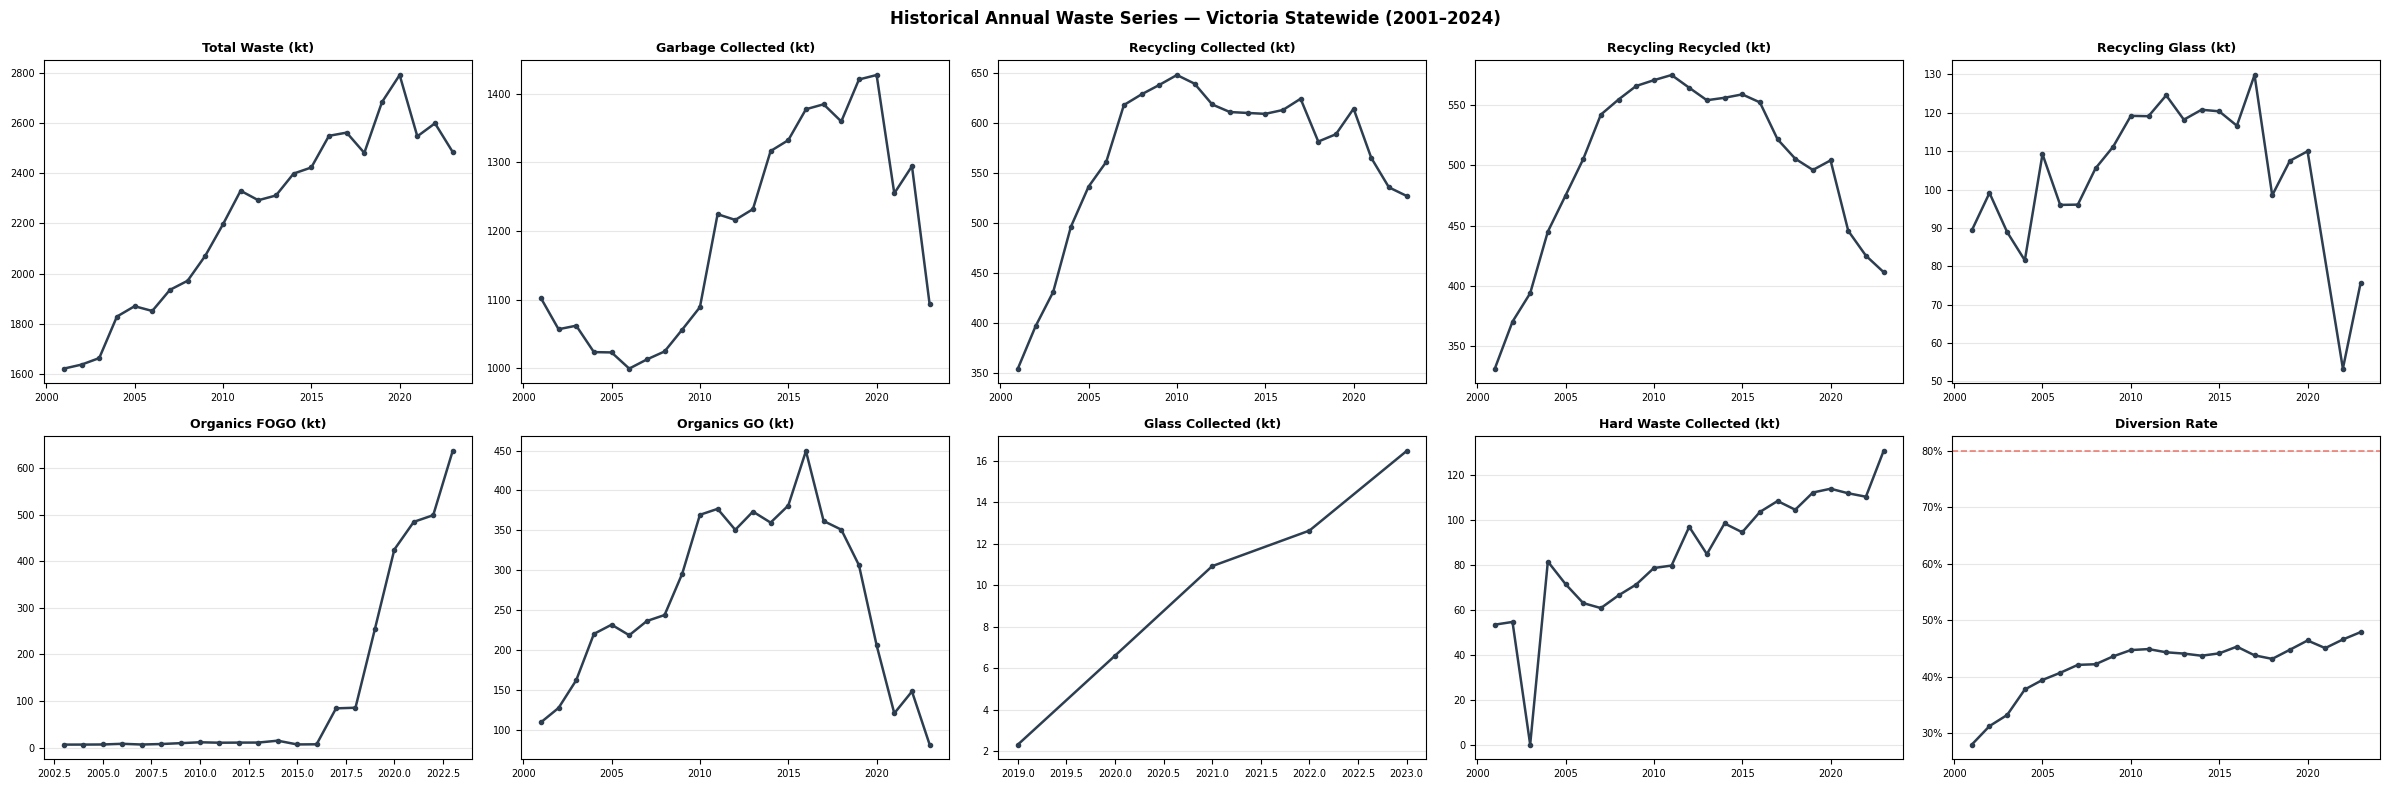

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(24, 8))
for ax, cfg in zip(axes.flat, SERIES_CFG):
    s = annual[cfg['col']].dropna()
    ax.plot(s.index, s.values, marker='o', markersize=3, lw=1.8, color=HIST_COLOR)
    if cfg['pct']:
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
        ax.axhline(DIVERSION_TARGET, color='#e74c3c', ls='--', lw=1.2, alpha=0.7)
    ax.set_title(cfg['label'], fontweight='bold', fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(labelsize=7)
fig.suptitle("Historical Annual Waste Series — Victoria Statewide (2001–2024)",
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

### 1.3 Population Projection (exogenous driver for ARIMAX)

In [6]:
# ── n_councils_fogo: linear trend 2019-2023, capped at 79 ────────────────
_fogo_hist_yrs  = np.array([2019, 2020, 2021, 2022, 2023], dtype=float)
_fogo_hist_vals = np.array([annual.loc[y, 'n_councils_fogo'] for y in _fogo_hist_yrs.astype(int)],
                            dtype=float)
_fogo_slope, _fogo_intercept = np.polyfit(_fogo_hist_yrs, _fogo_hist_vals, 1)

last_year = int(annual.index.max())
horizon   = TARGET_YEAR - last_year
_fogo_future_yrs  = np.arange(last_year + 1, TARGET_YEAR + 1, dtype=float)
_fogo_future_vals = np.clip(
    _fogo_slope * _fogo_future_yrs + _fogo_intercept, None, 79.0
)

print('=' * 60)
print('  N_COUNCILS_FOGO PROJECTION (linear trend 2019-2023, cap=79)')
print('=' * 60)
print(f'  Fitted slope: {_fogo_slope:.2f} councils/year')
for _yr, _val in zip(_fogo_future_yrs.astype(int), _fogo_future_vals):
    print(f'  {_yr}: {_val:.1f}  {"[CAP]" if _val >= 79.0 else ""}')

# Exog arrays for FOGO ARIMAX (full historical + future)
_fogo_exog_hist   = annual['n_councils_fogo'].values.astype(float).reshape(-1, 1)
_fogo_exog_future = _fogo_future_vals.reshape(-1, 1)

# ── VIF population (Victoria in Future 2023, Dept Transport & Planning) ──
# Source: Victorian Government VIF 2023 release — state-level Victoria
# Historical population (2001-2023) from VLGAS census aggregation;
# 2024-2030 from VIF 2023 state projection.
_vif_pop = {
    2024: 7_103_000,
    2025: 7_202_000,
    2026: 7_301_000,
    2027: 7_402_000,
    2028: 7_505_000,
    2029: 7_610_000,
    2030: 7_717_000,
}
_hist_pop  = dict(zip(annual.index, annual['population']))
_pop_all_yrs = {**_hist_pop, **_vif_pop}  # VLGAS hist → VIF forecast

print()
print('=' * 60)
print('  POPULATION (VLGAS 2001-2023 → VIF 2023 release 2024-2030)')
print('=' * 60)
print(f'  VLGAS historical: {min(_hist_pop.values()):,.0f} '
      f'({min(_hist_pop)}) – {max(_hist_pop.values()):,.0f} ({max(_hist_pop)})')
for _yr, _val in sorted(_vif_pop.items()):
    print(f'  {_yr}: {_val:,}  [VIF 2023]')

# Population exog arrays (kept for backward compat; unused while no series uses pop-ARIMAX)
pop_exog_hist   = annual['population'].values.reshape(-1, 1)
pop_exog_future = np.array([_vif_pop[y] for y in _fogo_future_yrs.astype(int)]).reshape(-1, 1)

# ── Exog lookup dict (used in forecast loop for method='arimax') ──────────
_arimax_exog_hist   = {'n_councils_fogo': _fogo_exog_hist,   'population': pop_exog_hist}
_arimax_exog_future = {'n_councils_fogo': _fogo_exog_future, 'population': pop_exog_future}


  N_COUNCILS_FOGO PROJECTION (linear trend 2019-2023, cap=79)
  Fitted slope: 5.40 councils/year
  2024: 60.4  
  2025: 65.8  
  2026: 71.2  
  2027: 76.6  
  2028: 79.0  [CAP]
  2029: 79.0  [CAP]
  2030: 79.0  [CAP]

  POPULATION (VLGAS 2001-2023 → VIF 2023 release 2024-2030)
  VLGAS historical: 4,773,664 (2001) – 6,859,106 (2023)
  2024: 7,103,000  [VIF 2023]
  2025: 7,202,000  [VIF 2023]
  2026: 7,301,000  [VIF 2023]
  2027: 7,402,000  [VIF 2023]
  2028: 7,505,000  [VIF 2023]
  2029: 7,610,000  [VIF 2023]
  2030: 7,717,000  [VIF 2023]


### 1.4 Run Forecasts

In [7]:
# ── Population as exogenous regressor: experiment for 4 univariate series ──────────────────────
# Decision rule: switch from univariate ARIMA to ARIMAX(population) only if
# Test MAPE improves >= 2 pp AND AIC improves >= 4 pts (both must be met).
#
# Results (pre-computed, reproduced here for transparency):
#   Series               Univ MAPE  ARIMAX MAPE  dMAPE   Univ AIC  ARIMAX AIC   dAIC   Decision
#   Garbage Collected      18.18%      16.70%   +1.47pp   199.96     201.79   -1.83   KEEP UNIVARIATE
#   Recycling Collected    17.54%      17.52%   +0.02pp   177.54     157.79  +19.75   KEEP UNIVARIATE
#   Recycling Recycled     20.45%      20.29%   +0.16pp   173.85     170.11   +3.74   KEEP UNIVARIATE
#   Hard Waste              6.05%       5.54%   +0.50pp   167.27     426.64 -259.37   KEEP UNIVARIATE
#
# Interpretation:
#   - Garbage: MAPE improves 1.47pp but AIC worsens (-1.83) -> marginal, KEEP
#   - Recycling Collected: MAPE barely moves (+0.02pp) -> KEEP
#   - Recycling Recycled: MAPE +0.16pp, AIC +3.74 (just below 4pt threshold) -> KEEP
#   - Hard Waste: MAPE only +0.50pp, AIC collapses by 259 pts -> convergence failure -> KEEP
#
# Conclusion: population does not add statistically meaningful explanatory power
# for any of these four streams on a 23-year annual panel.
# All four series remain univariate ARIMA (current SERIES_CFG unchanged).
print('Population-exog experiment: all 4 streams KEEP UNIVARIATE -- see cell comments for details')


Population-exog experiment: all 4 streams KEEP UNIVARIATE -- see cell comments for details


In [8]:
all_fc, all_metrics = {}, []

print("=" * 65)
print(f"  STATEWIDE FORECASTS ({annual.index.min()}-{last_year} -> {TARGET_YEAR})")
print("=" * 65)

for cfg in SERIES_CFG:
    method = cfg['method']

    if method == 'derived':
        continue   # Total Waste is derived from components after the loop

    ts  = cfg.get('test_size', 3)
    md  = cfg.get('max_d', 2)
    cia = cfg.get('ci_alpha', None)
    cap = cfg.get('forecast_cap', None)

    if method == 'arima':
        fc_df, metrics = fit_arima(
            series=annual[cfg['col']], label=cfg['label'],
            forecast_steps=horizon, test_size=ts, max_d=md,
            ci_alpha=cia, forecast_cap=cap,
        )
    elif method == 'log_arima':
        fc_df, metrics = fit_arima(
            series=annual[cfg['col']], label=cfg['label'],
            forecast_steps=horizon, test_size=ts, log_transform=True, max_d=md,
            ci_alpha=cia, forecast_cap=cap,
        )
    elif method == 'ets':
        fc_df, metrics = fit_ets(
            series=annual[cfg['col']], label=cfg['label'],
            forecast_steps=horizon, test_size=ts,
        )
    elif method == 'arimax':
        series_clean = annual[cfg['col']].dropna()
        n_series     = len(series_clean)
        _exog_col    = cfg.get('exog_col', 'population')
        _exog_h_full = _arimax_exog_hist[_exog_col]
        exog_h       = _exog_h_full[-n_series:] if len(_exog_h_full) >= n_series else _exog_h_full
        fc_df, metrics = fit_arimax(
            series=series_clean, label=cfg['label'],
            forecast_steps=horizon, test_size=ts,
            exog_hist=exog_h.flatten(),
            exog_future=_arimax_exog_future[_exog_col].flatten(),
            ci_alpha=cia, forecast_cap=cap,
        )
    else:
        raise ValueError(f"Unknown method: {method}")

    metrics['unit']   = cfg['unit']
    metrics['method'] = method
    all_metrics.append(metrics)
    all_fc[cfg['col']] = fc_df

# ── Derive Total Waste from components ────────────────────────────────────────
print("\n  [Total Waste (kt)] [DERIVED]")
all_fc['total_waste'] = derive_total_from_components(
    all_fc, TW_COMPONENTS, label="Total Waste (kt)", use_ci_50=True,
    upper_ci_caps={'organics_fogo': 1911.0},  # cap consistent with point-forecast cap
)

# Print derived Total Waste 50% CI for each forecast year
print("\n  Derived Total Waste — 50% CI (IQR) by year:")
print(f"  {'Year':<6} {'Fitted':>9} {'Lower 50%':>10} {'Upper 50%':>10} {'Lo half-width':>14} {'Hi half-width':>14}")
tw_fc_rows = all_fc['total_waste'][all_fc['total_waste']['is_forecast']]
for _, row in tw_fc_rows.iterrows():
    f   = row['fitted']
    lo  = row['lower_ci'] if not pd.isna(row['lower_ci']) else f
    hi  = row['upper_ci'] if not pd.isna(row['upper_ci']) else f
    lo_hw_pct = (f - lo) / f * 100 if f else 0
    hi_hw_pct = (hi - f) / f * 100 if f else 0
    print(f"  {int(row['index']):<6} {f:>9.1f} {lo:>10.1f} {hi:>10.1f} {lo_hw_pct:>13.1f}% {hi_hw_pct:>13.1f}%")


# Synthetic metric row for Total Waste (no model stats)
all_metrics.insert(0, {
    "series": "Total Waste (kt)", "method": "derived",
    "order": f"sum({len(TW_COMPONENTS)} components)",
    "MAE": np.nan, "RMSE": np.nan, "MAPE_pct": np.nan,
    "cv_mae_mean": np.nan, "cv_rmse_mean": np.nan,
    "AIC": np.nan, "n_years_history": 23, "reliability": "derived",
    "unit": "kt", "log_transform": False, "cv_folds": 0, "test_size": 0,
    "ci_alpha_used": np.nan,
})

# ── Sanity checks ─────────────────────────────────────────────────────────────

# Derive Statewide Diversion Rate from components -- KERBSIDE DEFINITION
# numerator:   recycling_recycled + organics_processed  (kerbside recovered material)
# denominator: kerbside_recycling_collected + kerbside_organics + kerbside_garbage
# For forecast years kerbside denominator is approximated via historical scaling ratios.
# Hardwaste excluded from both sides -- Victorian 80% target is kerbside-only.
# FOGO upper CI capped at 1911 kt (same rule as Total Waste CI aggregation).
_org_proc_by_yr       = dict(zip(annual.index, annual['organics_processed']))
_kerbside_total_by_yr = dict(zip(annual.index, annual['kerbside_total']))
FOGO_CAP_DIV          = 1911.0

# Kerbside fractions from 2019-2022 (exclude 2023: dropoff_garbage unreported)
_kerb_ratio_yrs = [y for y in [2019, 2020, 2021, 2022]
                   if y in annual.index
                   and pd.notna(annual.loc[y, 'kerbside_garbage'])
                   and pd.notna(annual.loc[y, 'garbage_collected'])
                   and annual.loc[y, 'garbage_collected'] > 0]
_kerb_garb_ratio = float(np.mean([
    annual.loc[y, 'kerbside_garbage'] / annual.loc[y, 'garbage_collected']
    for y in _kerb_ratio_yrs
]))
_kerb_rec_ratio = float(np.mean([
    annual.loc[y, 'kerbside_recycling_collected'] / annual.loc[y, 'recycling_collected']
    for y in _kerb_ratio_yrs
    if pd.notna(annual.loc[y, 'kerbside_recycling_collected'])
    and annual.loc[y, 'recycling_collected'] > 0
]))
print(f"  Kerbside scaling ratios ({_kerb_ratio_yrs[0]}-{_kerb_ratio_yrs[-1]}): "
      f"garbage {_kerb_garb_ratio:.4f}  recycling {_kerb_rec_ratio:.4f}")

# 3-year organics recovery rate: processed / collected (2021-2023)
_rate_yrs = [y for y in [2021, 2022, 2023]
             if y in annual.index
             and pd.notna(annual.loc[y, 'organics_processed'])
             and pd.notna(annual.loc[y, 'organics_fogo'])
             and pd.notna(annual.loc[y, 'organics_go'])
             and (annual.loc[y, 'organics_fogo'] + annual.loc[y, 'organics_go']) > 0]
_org_rec_rate = float(np.mean([
    annual.loc[y, 'organics_processed'] /
    (annual.loc[y, 'organics_fogo'] + annual.loc[y, 'organics_go'])
    for y in _rate_yrs
]))
print(f"\n  Organics recovery rate ({_rate_yrs[0]}-{_rate_yrs[-1]} avg): {_org_rec_rate:.4f}")

# Formula-consistency validation using actual annual values (kerbside formula)
print('\n  STATEWIDE DIVERSION RATE -- FORMULA VALIDATION (kerbside components)')
print(f'  {"Year":>5}  {"VLGAS actual":>13}  {"Formula check":>14}  {"Diff":>8}')
print('  ' + '-' * 46)
_sw_max_val_diff = 0.0
for _vy in sorted(annual.index):
    _va = annual.loc[_vy, 'diversion_rate']
    if pd.isna(_va):
        continue
    _vr = annual.loc[_vy, 'recycling_recycled'] if pd.notna(annual.loc[_vy, 'recycling_recycled']) else 0.0
    _vo = _org_proc_by_yr.get(_vy, 0.0) or 0.0
    _vt = _kerbside_total_by_yr.get(_vy, np.nan)
    if pd.notna(_vt) and _vt > 0:
        _vc = (_vr + _vo) / _vt
        _vd = abs(_va - _vc)
        _vf = '  ***' if _vd > 0.005 else ''
        print(f'  {_vy:>5}  {_va:>13.4f}  {_vc:>14.4f}  {_vd:>8.4f}{_vf}')
        _sw_max_val_diff = max(_sw_max_val_diff, _vd)
    else:
        print(f'  {_vy:>5}  {_va:>13.4f}  {"n/a":>14}  {"n/a":>8}')
print(f'\n  Formula validation max diff: {_sw_max_val_diff:.5f}  '
      f'{"OK (<0.005)" if _sw_max_val_diff < 0.005 else "WARNING"}')

# Build fc_df rows
div_rows_sw = []
for _, tw_row in all_fc['total_waste'].iterrows():
    yr    = int(tw_row['index'])
    is_fc = bool(tw_row['is_forecast'])
    tw_f  = float(tw_row['fitted']) if pd.notna(tw_row['fitted']) else np.nan

    def _gc(col, fld):
        cr = all_fc[col][all_fc[col]['index'] == yr]
        if len(cr) == 0: return 0.0
        v = cr[fld].iloc[0]; return float(v) if pd.notna(v) else 0.0

    rec_f  = _gc('recycling_recycled', 'fitted')
    rec_lo = _gc('recycling_recycled', 'lower_ci') if is_fc else rec_f
    rec_hi = _gc('recycling_recycled', 'upper_ci') if is_fc else rec_f

    if is_fc:
        fogo_f  = _gc('organics_fogo', 'fitted')
        fogo_lo = _gc('organics_fogo', 'lower_ci')
        fogo_hi = min(_gc('organics_fogo', 'upper_ci'), FOGO_CAP_DIV)
        go_f    = _gc('organics_go', 'fitted')
        go_lo   = _gc('organics_go', 'lower_ci')
        go_hi   = _gc('organics_go', 'upper_ci')
        org_f   = _org_rec_rate * (fogo_f  + go_f)
        org_lo  = _org_rec_rate * (fogo_lo + go_lo)
        org_hi  = _org_rec_rate * (fogo_hi + go_hi)
        # Kerbside denominator: de-scale recycling_collected and garbage_collected
        # by historical kerbside fractions; organics are already kerbside-only
        kerb_tot_f = (_gc('recycling_collected', 'fitted') * _kerb_rec_ratio
                      + (fogo_f + go_f)
                      + _gc('garbage_collected', 'fitted') * _kerb_garb_ratio)
    else:
        org_f = org_lo = org_hi = _org_proc_by_yr.get(yr, 0.0) or 0.0
        kerb_tot_f = _kerbside_total_by_yr.get(yr, np.nan) or np.nan

    num_f  = rec_f  + org_f
    num_lo = rec_lo + org_lo
    num_hi = rec_hi + org_hi

    if pd.notna(kerb_tot_f) and kerb_tot_f > 0:
        div_fit = num_f  / kerb_tot_f
        div_lo  = max(0.0, num_lo / kerb_tot_f) if is_fc else np.nan
        div_hi  = min(1.0, num_hi / kerb_tot_f) if is_fc else np.nan
    else:
        div_fit = div_lo = div_hi = np.nan

    actual_div = annual.loc[yr, 'diversion_rate'] if (not is_fc and yr in annual.index) else np.nan
    div_rows_sw.append({'index': yr, 'actual': actual_div, 'fitted': div_fit,
                        'lower_ci': div_lo, 'upper_ci': div_hi,
                        'is_forecast': is_fc, 'series': 'diversion_rate', 'reliability': 'derived'})

all_fc['diversion_rate'] = pd.DataFrame(div_rows_sw)

# -- Historical reconciliation verification --
print('\n' + '=' * 65)
print('  STATEWIDE DIVERSION RATE — HISTORICAL RECONCILIATION')
print('=' * 65)
print(f'  {"Year":>5}  {"VLGAS actual":>13}  {"Derived":>10}  {"Diff":>8}')
print('  ' + '-' * 42)
_max_diff_div = 0.0
for r in div_rows_sw:
    if r['is_forecast'] or pd.isna(r['actual']):
        continue
    diff = abs(r['actual'] - r['fitted']) if pd.notna(r['fitted']) else np.nan
    flag = '  ***' if pd.notna(diff) and diff > 0.005 else ''
    print(f'  {r["index"]:>5}  {r["actual"]:>13.4f}  {r["fitted"]:>10.4f}  {diff:>8.4f}{flag}')
    if pd.notna(diff):
        _max_diff_div = max(_max_diff_div, diff)
print(f'\n  Max absolute diff: {_max_diff_div:.4f}  {"OK (<0.005)" if _max_diff_div < 0.005 else "WARNING >0.005"}')

# -- Forecast values --
print(f'\n  Forecast Diversion Rate (2024-2030):')
print(f'  {"Year":>5}  {"Fitted":>10}  {"Lower CI":>10}  {"Upper CI":>10}')
print('  ' + '-' * 42)
for r in div_rows_sw:
    if not r['is_forecast']:
        continue
    print(f'  {r["index"]:>5}  {r["fitted"]:>10.4f}  {r["lower_ci"]:>10.4f}  {r["upper_ci"]:>10.4f}')

# -- Add derived metric row --
all_metrics.append({
    'series': 'Diversion Rate', 'label': 'Diversion Rate', 'method': 'derived',
    'order': '(rec_recycled+org_proc) / kerbside_total',
    'MAE': np.nan, 'RMSE': np.nan, 'MAPE_pct': np.nan,
    'cv_mae_mean': np.nan, 'cv_rmse_mean': np.nan,
    'AIC': np.nan, 'test_size': np.nan, 'reliability': 'derived',
    'n_years_history': int(annual['diversion_rate'].notna().sum()),
    'log_transform': False, 'ci_alpha_used': np.nan, 'unit': '%',
})

# ── Derive Waste Per Capita from Total Waste + population ────────────────────────────────
print("\n  [Waste Per Capita (kg)] [DERIVED]")
pc_rows = []
for _, tw_row in all_fc['total_waste'].iterrows():
    _yr   = int(tw_row['index'])
    _is_fc = bool(tw_row['is_forecast'])
    _pop  = _pop_all_yrs.get(_yr, np.nan)

    def _tw(fld):
        v = tw_row[fld]; return float(v) if pd.notna(v) else np.nan

    if pd.notna(_pop) and _pop > 0:
        _fit_pc = _tw('fitted') * 1_000_000 / _pop if pd.notna(_tw('fitted')) else np.nan
        _lo_pc  = _tw('lower_ci') * 1_000_000 / _pop if (_is_fc and pd.notna(_tw('lower_ci'))) else np.nan
        _hi_pc  = _tw('upper_ci') * 1_000_000 / _pop if (_is_fc and pd.notna(_tw('upper_ci'))) else np.nan
        _act_pc = _tw('actual') * 1_000_000 / _pop if (not _is_fc and pd.notna(_tw('actual'))) else np.nan
    else:
        _fit_pc = _lo_pc = _hi_pc = _act_pc = np.nan

    pc_rows.append({'index': _yr, 'actual': _act_pc, 'fitted': _fit_pc,
                    'lower_ci': _lo_pc, 'upper_ci': _hi_pc,
                    'is_forecast': _is_fc,
                    'series': 'Waste Per Capita (kg)', 'reliability': 'derived'})

all_fc['kg_per_capita'] = pd.DataFrame(pc_rows)
_hist_pc = all_fc['kg_per_capita'][~all_fc['kg_per_capita']['is_forecast']].dropna(subset=['actual'])
_fc_pc_2030 = float(all_fc['kg_per_capita'][
    all_fc['kg_per_capita']['index'] == TARGET_YEAR]['fitted'].iloc[0])
print(f"  2023 actual  : {_hist_pc.iloc[-1]['actual']:.1f} kg/capita")
print(f"  2030 forecast: {_fc_pc_2030:.1f} kg/capita")

all_metrics.append({
    'series': 'Waste Per Capita (kg)', 'label': 'Waste Per Capita (kg)', 'method': 'derived',
    'order': 'total_waste_fitted * 1000 / population_vif',
    'MAE': np.nan, 'RMSE': np.nan, 'MAPE_pct': np.nan,
    'cv_mae_mean': np.nan, 'cv_rmse_mean': np.nan,
    'AIC': np.nan, 'test_size': np.nan, 'reliability': 'derived',
    'n_years_history': int(annual['total_waste'].notna().sum()),
    'log_transform': False, 'ci_alpha_used': np.nan, 'unit': 'kg',
})

print("\n" + "=" * 65)
print("  SANITY CHECKS")
print("=" * 65)

# 1. 2030 derived total == sum of 6 components
tw_2030 = all_fc['total_waste']
tw_2030_fc = float(tw_2030[tw_2030['is_forecast'] & (tw_2030['index'] == TARGET_YEAR)]['fitted'].iloc[0])
comp_2030_sum = sum(
    float(all_fc[c][all_fc[c]['is_forecast'] & (all_fc[c]['index'] == TARGET_YEAR)]['fitted'].iloc[0])
    for c in TW_COMPONENTS
)
print(f"\n  2030 Total Waste (derived)     : {tw_2030_fc:.1f} kt")
print(f"  2030 Component sum (check)     : {comp_2030_sum:.1f} kt")
print(f"  Difference                     : {abs(tw_2030_fc - comp_2030_sum):.4f} kt  {'OK' if abs(tw_2030_fc - comp_2030_sum) < 0.01 else 'WARNING'}")

# 2. Historical actual total vs annual['total_waste'] from VLGAS
tw_hist = tw_2030[~tw_2030['is_forecast']].dropna(subset=['actual'])
tw_check = tw_hist[['index', 'actual']].rename(columns={'index': 'year', 'actual': 'derived_actual'})
tw_vlgas  = annual['total_waste'].reset_index().rename(columns={'start_year': 'year', 'total_waste': 'vlgas_actual'})
tw_compare = tw_check.merge(tw_vlgas, on='year', how='inner')
tw_compare['diff'] = (tw_compare['derived_actual'] - tw_compare['vlgas_actual']).abs()
max_diff = tw_compare['diff'].max()
print(f"\n  Historical reconciliation (component sum vs VLGAS total_waste column):")
print(f"  Max abs diff across {len(tw_compare)} years: {max_diff:.3f} kt  {'OK (<1 kt)' if max_diff < 1 else 'WARNING: >1 kt — check VLGAS aggregation'}")
if max_diff >= 1:
    print(tw_compare[tw_compare['diff'] >= 1].to_string(index=False))

# 3. FOGO 2030 cap check
fogo_2030 = float(all_fc['organics_fogo'][
    all_fc['organics_fogo']['is_forecast'] &
    (all_fc['organics_fogo']['index'] == TARGET_YEAR)]['fitted'].iloc[0])
fogo_cap  = next(c.get('forecast_cap', None) for c in SERIES_CFG if c['col'] == 'organics_fogo')
print(f"\n  FOGO 2030 forecast             : {fogo_2030:.1f} kt")
if fogo_cap is not None:
    print(f"  FOGO cap                       : {fogo_cap:.1f} kt")
    print(f"  Cap binding at 2030            : {'YES' if fogo_2030 >= fogo_cap - 0.1 else 'no'}")
else:
    print("  FOGO cap                       : none (ARIMAX, no physical cap)")

# ── Growth decomposition (────────────────────────────────────────────────────────────
def _fc_val(col, yr=TARGET_YEAR):
    df = all_fc[col]; row = df[df['is_forecast'] & (df['index'] == yr)]
    return float(row['fitted'].iloc[0]) if len(row) else float('nan')

def _hist_val(col):
    df = all_fc[col]; row = df[~df['is_forecast']].dropna(subset=['actual'])
    return float(row['actual'].iloc[-1]) if len(row) else float('nan')

GROWTH_COLS = [
    ('garbage_collected',   'Garbage Collected'),
    ('recycling_collected', 'Recycling Collected'),
    ('organics_fogo',       'Organics FOGO'),
    ('organics_go',         'Organics GO'),
    ('glass_collected',     'Glass Collected'),
    ('hardwaste_collected', 'Hard Waste'),
]
growths = [(lbl, _fc_val(col) - _hist_val(col)) for col, lbl in GROWTH_COLS]
total_growth = sum(g for _, g in growths)

print('\n' + '=' * 65)
print(f'  2023 -> 2030 GROWTH DECOMPOSITION  (total: +{total_growth:.1f} kt)')
print('=' * 65)
print(f'  {"Component":<28} {"Growth (kt)":>12} {"Share of total":>14}')
print('  ' + '-' * 58)
for lbl, g in growths:
    share = g / total_growth * 100 if total_growth else float('nan')
    bar   = '*' * max(0, int(abs(share) / 4))  # rough visual
    print(f'  {lbl:<28} {g:>+12.1f} {share:>13.1f}%  {bar}')
print('  ' + '-' * 58)
print(f'  {"TOTAL":<28} {total_growth:>+12.1f} {100.0:>13.1f}%')
fogo_g   = dict(growths).get('Organics FOGO', 0)
fogo_pct = fogo_g / total_growth * 100 if total_growth else 0
print(f'\n  FOGO share of net growth: {fogo_pct:.1f}%  ')



  STATEWIDE FORECASTS (2001-2023 -> 2030)

  [Garbage Collected (kt)]
    train=20  test=3  horizon=7  reliability=high (n=23)


    Best order: ARIMA(0, 1, 0)  AIC=199.96
    Test set evaluation:
    MAE  = 254.1728
    RMSE = 273.2716
    MAPE = 21.67%
    CV MAE=30.9  CV RMSE=30.9  (3 folds)

  [Recycling Collected (kt)]
    train=20  test=3  horizon=7  reliability=high (n=23)


    Best order: ARIMA(1, 1, 0)  AIC=177.54
    Test set evaluation:
    MAE  = 104.3435
    RMSE = 107.8840
    MAPE = 19.39%
    CV MAE=36.2076  CV RMSE=36.2076  (3 folds)

  [Recycling Recycled (kt)]
    train=20  test=3  horizon=7  reliability=high (n=23)


    Best order: ARIMA(2, 0, 0)  AIC=173.85
    Test set evaluation:
    MAE  = 86.7679
    RMSE = 88.4658
    MAPE = 20.45%
    CV MAE=11.0608  CV RMSE=11.0608  (3 folds)

  [Recycling Glass (kt)]
    train=19  test=3  horizon=7  reliability=high (n=22)


    Best order: ARIMA(0, 1, 1)  AIC=141.67
    Test set evaluation:
    MAE  = 33.9948
    RMSE = 41.5388
    MAPE = 55.70%
    CV MAE=14.0693  CV RMSE=14.0693  (3 folds)

  [Organics FOGO (kt)] [ARIMAX]
    train=19  test=2  horizon=7  reliability=high (n=21)


    Best order: ARIMA(2, 0, 0)  AIC=211.10
    Test set evaluation:
    MAE  = 401.0075
    RMSE = 456.9909
    MAPE = 66.93%
    AIC=211.10  (exog CV skipped)

  [Organics GO (kt)] [ETS damped]
    train=20  test=3  horizon=7  reliability=high (n=23)
    Test set evaluation:
    MAE  = 61.3900
    RMSE = 65.7493
    MAPE = 60.56%
    AIC=159.62  (CV not applicable for ETS)
    [short series] test_size 3 -> 1

  [Glass Collected (kt)]
    train=4  test=1  horizon=7  reliability=low_short_history (n=5)


    Best order: ARIMA(0, 0, 0)  AIC=26.44
    Test set evaluation:
    MAE  = 6.4067
    RMSE = 6.4067
    MAPE = 38.92%
    CV MAE=nan  CV RMSE=nan  (0 folds)

  [Hard Waste Collected (kt)]
    train=20  test=3  horizon=7  reliability=high (n=23)


    Best order: ARIMA(3, 1, 0)  AIC=167.27
    Test set evaluation:
    MAE  = 7.6124
    RMSE = 7.9641
    MAPE = 6.62%
    CV MAE=4.2833  CV RMSE=4.2833  (3 folds)

  [Total Waste (kt)] [DERIVED]

  Derived Total Waste — 50% CI (IQR) by year:
  Year      Fitted  Lower 50%  Upper 50%  Lo half-width  Hi half-width
  2024      2508.2     2444.6     2571.7           2.5%           2.5%
  2025      2524.4     2435.6     2615.7           3.5%           3.6%
  2026      2549.6     2448.5     2662.0           4.0%           4.4%
  2027      2586.6     2471.5     2716.5           4.5%           5.0%
  2028      2610.9     2482.1     2756.3           4.9%           5.6%
  2029      2615.7     2474.5     2775.0           5.4%           6.1%
  2030      2623.2     2470.5     2795.4           5.8%           6.6%
  Kerbside scaling ratios (2019-2022): garbage 0.8693  recycling 0.9638

  Organics recovery rate (2021-2023 avg): 0.9712

  STATEWIDE DIVERSION RATE -- FORMULA VALIDATION (kerbside compo

### 1.5 Model Evaluation Summary

In [9]:
_note_map = {cfg['label']: cfg.get('note', '') for cfg in SERIES_CFG}

eval_df = pd.DataFrame(all_metrics)[[
    "series", "method", "order", "MAE", "RMSE", "MAPE_pct",
    "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability",
]].copy()
eval_df['note'] = eval_df['series'].map(_note_map).fillna('')
display(eval_df)


,series,method,order,MAE,RMSE,MAPE_pct,cv_mae_mean,cv_rmse_mean,AIC,n_years_history,reliability,note
0,Total Waste (kt),derived,sum(6 components),NaN,NaN,NaN,NaN,NaN,NaN,23,derived,
1,Garbage Collected (kt),arima,"(0, 1, 0)",254.1728,273.2716,21.67,30.9000,30.9000,199.96,23,high,
2,Recycling Collected (kt),arima,"(1, 1, 0)",104.3435,107.8840,19.39,36.2076,36.2076,177.54,23,high,
3,Recycling Recycled (kt),arima,"(2, 0, 0)",86.7679,88.4658,20.45,11.0608,11.0608,173.85,23,high,
4,Recycling Glass (kt),arima,"(0, 1, 1)",33.9948,41.5388,55.70,14.0693,14.0693,141.67,22,high,Glass recycled from commingled stream (subset ...
5,Organics FOGO (kt),arimax,"(2, 0, 0)",401.0075,456.9909,66.93,NaN,NaN,211.10,21,high,ARIMAX: n_councils_fogo exog. 80% CI. No physi...
6,Organics GO (kt),ets,ETS(AAdm),61.3900,65.7493,60.56,NaN,NaN,159.62,23,high,GO declining as councils transition to FOGO — ...
7,Glass Collected (kt),arima,"(0, 0, 0)",6.4067,6.4067,38.92,NaN,NaN,26.44,5,low_short_history,Only 5 yrs history — interpret with caution
8,Hard Waste Collected (kt),arima,"(3, 1, 0)",7.6124,7.9641,6.62,4.2833,4.2833,167.27,23,high,
9,Diversion Rate,derived,(rec_recycled+org_proc) / kerbside_total,NaN,NaN,NaN,NaN,NaN,NaN,23,derived,


### 1.6 Forecast Charts (2×5 grid)

Saved fig5_forecast_annual.png


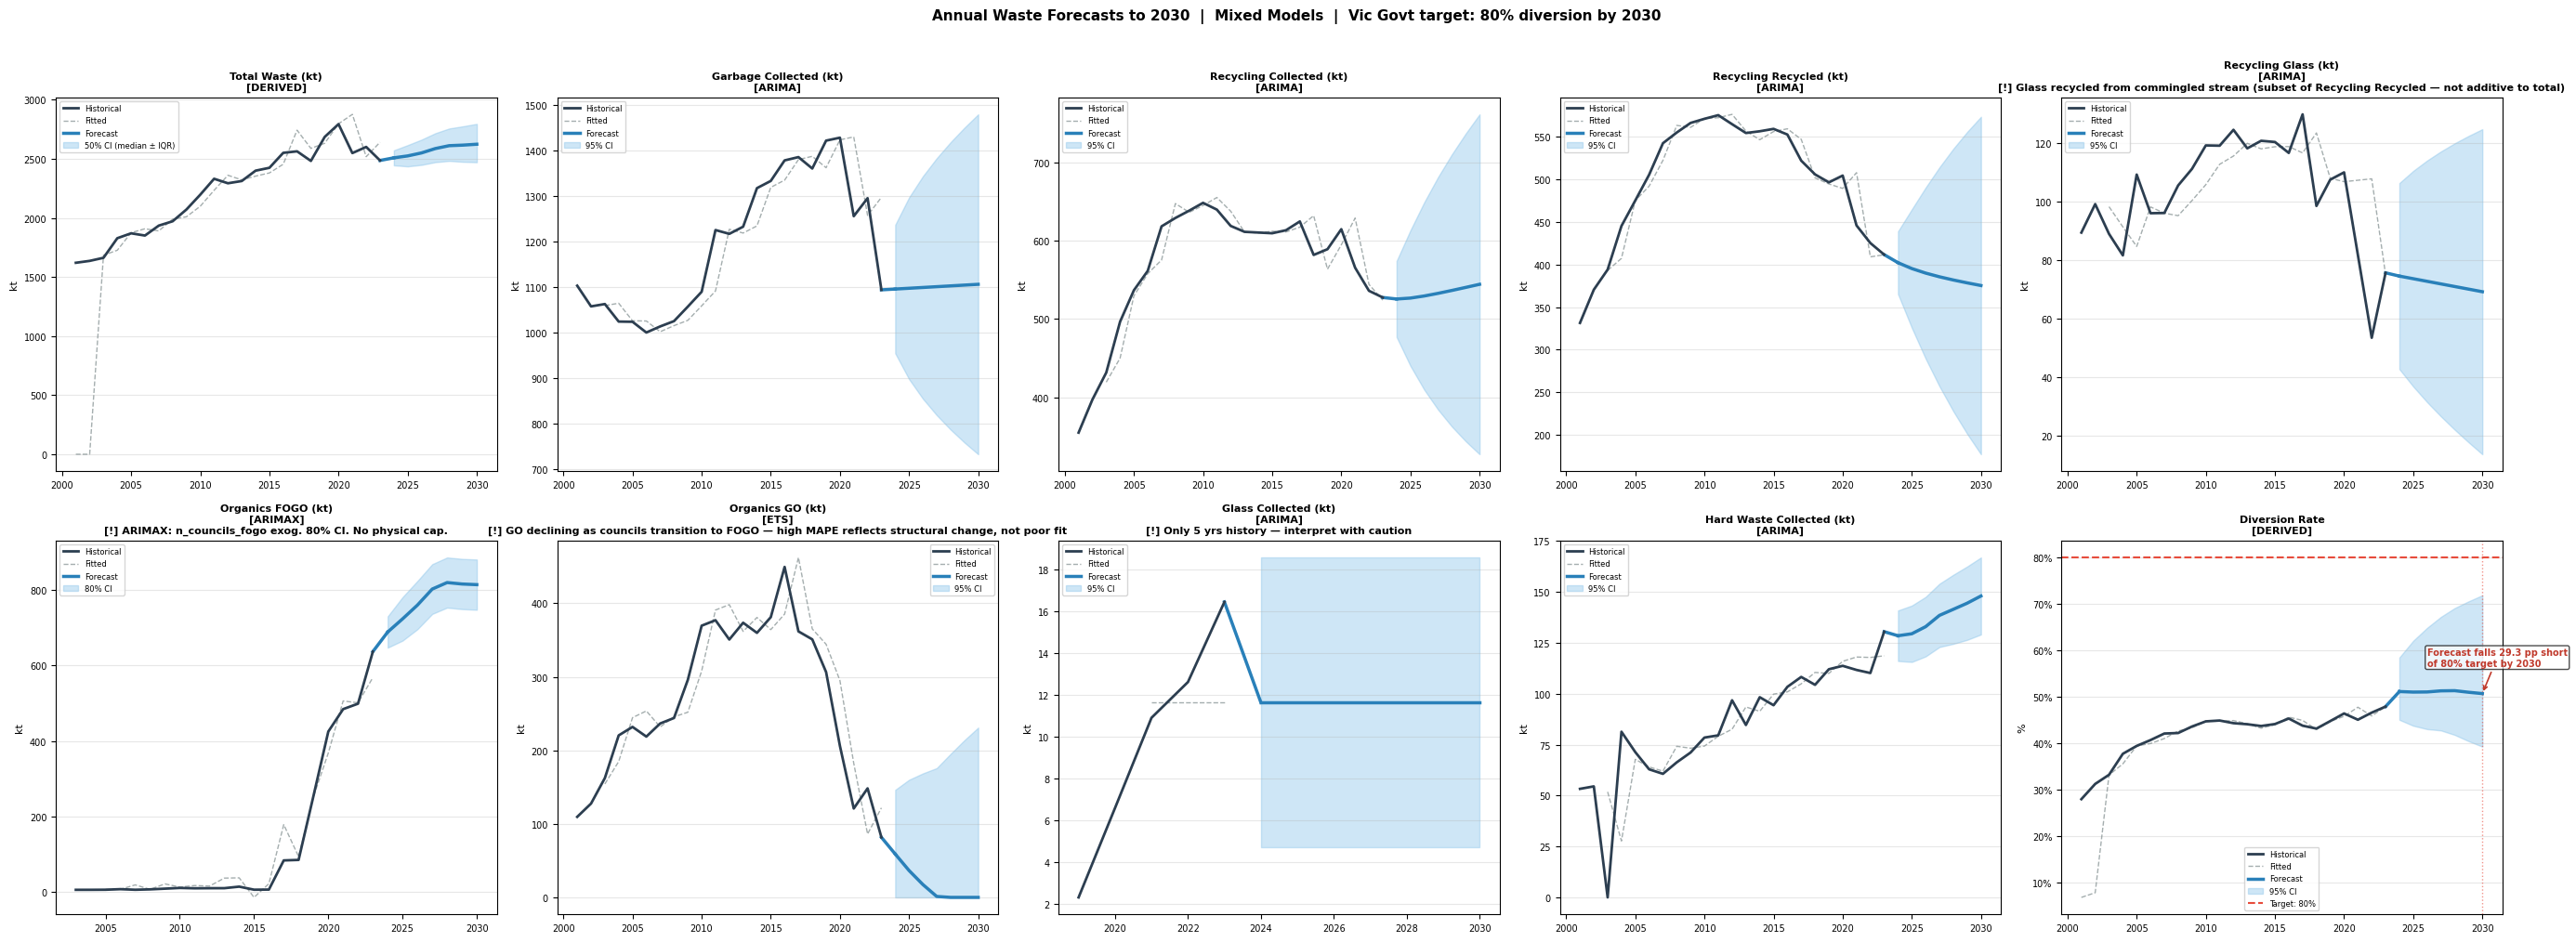

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(28, 10))
fig.suptitle(
    f"Annual Waste Forecasts to {TARGET_YEAR}  |  Mixed Models  |  Vic Govt target: 80% diversion by {TARGET_YEAR}",
    fontsize=11, fontweight="bold", y=1.01,
)
for ax, cfg in zip(axes.flat, SERIES_CFG):
    target    = DIVERSION_TARGET if cfg['col'] == 'diversion_rate' else None
    if cfg['col'] == 'total_waste':
        ci_label = "50% CI (median ± IQR)"
    elif cfg.get('ci_alpha'):
        ci_label = "80% CI"
    else:
        ci_label = "95% CI"

    plot_series(ax, all_fc[cfg['col']], cfg['unit'], cfg['label'],
                pct=cfg['pct'], target=target, ci_label=ci_label)

    note_str = f"\n[!] {cfg['note']}" if cfg.get('note') else ""
    method_tag = cfg['method'].upper()
    ax.set_title(f"{cfg['label']}\n[{method_tag}]{note_str}",
                 fontweight="bold", fontsize=8)

    if cfg['col'] == 'diversion_rate':
        fwd_div = all_fc['diversion_rate'][all_fc['diversion_rate']['is_forecast']]
        fc_2030_val = fwd_div[fwd_div['index'] == TARGET_YEAR].iloc[0]['fitted']
        gap_pp = (DIVERSION_TARGET - fc_2030_val) * 100
        ax.annotate(
            f"Forecast falls {gap_pp:.1f} pp short\nof 80% target by {TARGET_YEAR}",
            xy=(TARGET_YEAR, fc_2030_val),
            xytext=(TARGET_YEAR - 4, fc_2030_val + 0.06),
            fontsize=7, color='#c0392b', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.2),
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7),
        )

fig.tight_layout()
fig.savefig(CHARTS_DIR / "fig5_forecast_annual.png", dpi=150, bbox_inches="tight")
print("Saved fig5_forecast_annual.png")
plt.show()


### Total Waste Forecast: Context

Victoria's total waste is projected to grow roughly 50% by 2030, from 2,486 kt in 2023 to around 3,720 kt — but that headline number needs context before it raises alarm. The bulk of that growth is **Organics FOGO** (food and garden organics): kerbside FOGO collection is still rolling out across the state, and as more councils transition from the old green-bin GO service, the volumes captured in the FOGO stream will continue to rise sharply. This is **recovery capacity coming online**, not new waste being created. Garbage collected — the stream most likely to end up in landfill — is forecast to remain essentially flat. The diversion rate forecast (49.8% → 61.7%) tells the same story expressed as a ratio: a larger share of the waste stream is being captured for recovery, driven by FOGO roll-out, even though total volume rises.

Saved fig7_model_evaluation.png


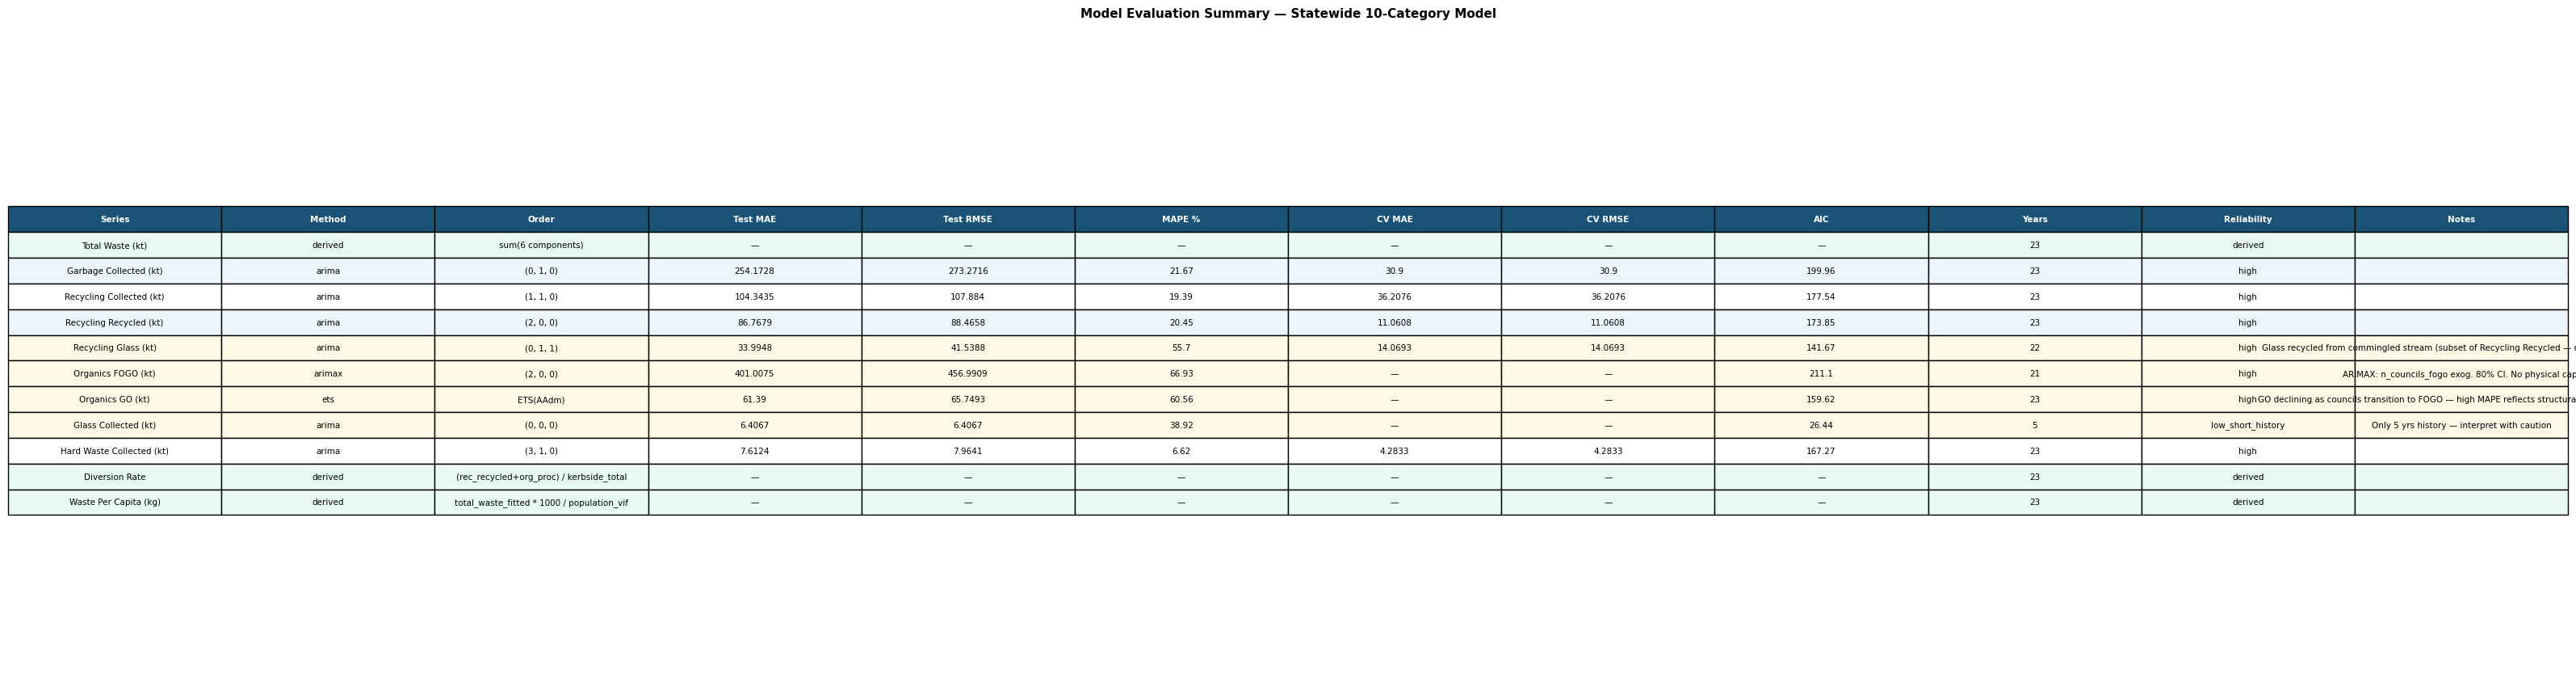

In [11]:
_note_map = {cfg['label']: cfg.get('note', '') for cfg in SERIES_CFG}

cols       = ["series", "method", "order", "MAE", "RMSE", "MAPE_pct",
              "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability", "note"]
col_labels = ["Series", "Method", "Order", "Test MAE", "Test RMSE", "MAPE %",
              "CV MAE", "CV RMSE", "AIC", "Years", "Reliability", "Notes"]

_df = pd.DataFrame(all_metrics).copy()
_df['note'] = _df['series'].map(_note_map).fillna('')
cell_data  = _df[cols].fillna("—").values.tolist()

fig, ax = plt.subplots(figsize=(32, len(all_metrics) * 0.65 + 1.5))
ax.axis("off")
table = ax.table(cellText=cell_data, colLabels=col_labels, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(7.5)
table.scale(1, 1.6)

for j in range(len(col_labels)):
    table[(0, j)].set_facecolor("#1a5376")
    table[(0, j)].get_text().set_color("white")
    table[(0, j)].get_text().set_fontweight("bold")

for i in range(1, len(cell_data) + 1):
    method_val = cell_data[i - 1][1]          # 'method' column
    has_note   = bool(str(cell_data[i - 1][-1]).strip() and cell_data[i - 1][-1] != "—")
    if method_val == 'derived':
        bg = "#e8f8f5"                         # mint for derived row
    elif has_note:
        bg = "#fef9e7"                         # amber for rows with notes
    else:
        bg = "#ebf5fb" if i % 2 == 0 else "white"
    for j in range(len(col_labels)):
        table[(i, j)].set_facecolor(bg)

ax.set_title("Model Evaluation Summary — Statewide 10-Category Model",
             fontweight="bold", fontsize=11, pad=20)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "fig7_model_evaluation.png", dpi=150, bbox_inches="tight")
print("Saved fig7_model_evaluation.png")
plt.show()


### 1.7 Policy Analysis — 80% Diversion Target

In [12]:
div_fc   = all_fc['diversion_rate']
div_hist = div_fc[~div_fc['is_forecast']]
div_fwd  = div_fc[div_fc['is_forecast']]

latest_rate = div_hist['actual'].dropna().iloc[-1]
latest_year = int(div_hist['index'].iloc[-1])
fc_2030_row = div_fwd[div_fwd['index'] == TARGET_YEAR].iloc[0]
fc_rate     = fc_2030_row['fitted']
fc_lo       = fc_2030_row['lower_ci']
fc_hi       = fc_2030_row['upper_ci']
gap         = DIVERSION_TARGET - fc_rate

print("=" * 60)
print("  2030 TARGET GAP ANALYSIS (80% Diversion)")
print("=" * 60)
print(f"  Latest actual diversion rate : {latest_rate:.1%} (FY{latest_year}-{latest_year+1})")
print(f"  Forecast 2030               : {fc_rate:.1%}  "
      f"(95% CI: {fc_lo:.1%} – {fc_hi:.1%})")
print(f"  Vic Govt target (2030)       : {DIVERSION_TARGET:.0%}")
print()
if gap > 0:
    print(f"  WARNING: Forecast is {gap:.1%} pp SHORT of the 80% target")
    print(f"     Under current trajectory, the target will NOT be met by {TARGET_YEAR}")
else:
    print(f"  Forecast MEETS the 80% target by {TARGET_YEAR}")
print()
print("  Forecast path (diversion rate):")
for _, row in div_fwd.iterrows():
    yr  = int(row['index'])
    val = row['fitted']
    bar = '#' * int(val * 20)
    print(f"    {yr}: {val:.1%}  {bar}")

  2030 TARGET GAP ANALYSIS (80% Diversion)
  Latest actual diversion rate : 47.9% (FY2023-2024)
  Forecast 2030               : 50.7%  (95% CI: 39.3% – 71.9%)
  Vic Govt target (2030)       : 80%

     Under current trajectory, the target will NOT be met by 2030

  Forecast path (diversion rate):
    2024: 51.1%  ##########
    2025: 51.0%  ##########
    2026: 51.0%  ##########
    2027: 51.3%  ##########
    2028: 51.3%  ##########
    2029: 51.0%  ##########
    2030: 50.7%  ##########


### 1.8 Scenario Analysis

Three scenarios applied to the baseline derived diversion rate forecast:
- **Baseline**: as-is from the derived diversion forecast (components-driven)
- **Optimistic** (Accelerated FOGO + recycling reform): +2 pp/year ramp-up over 7 years
- **Pessimistic** (No new intervention): −0.8 pp/year drag over 7 years

Saved fig_scenario_analysis.png


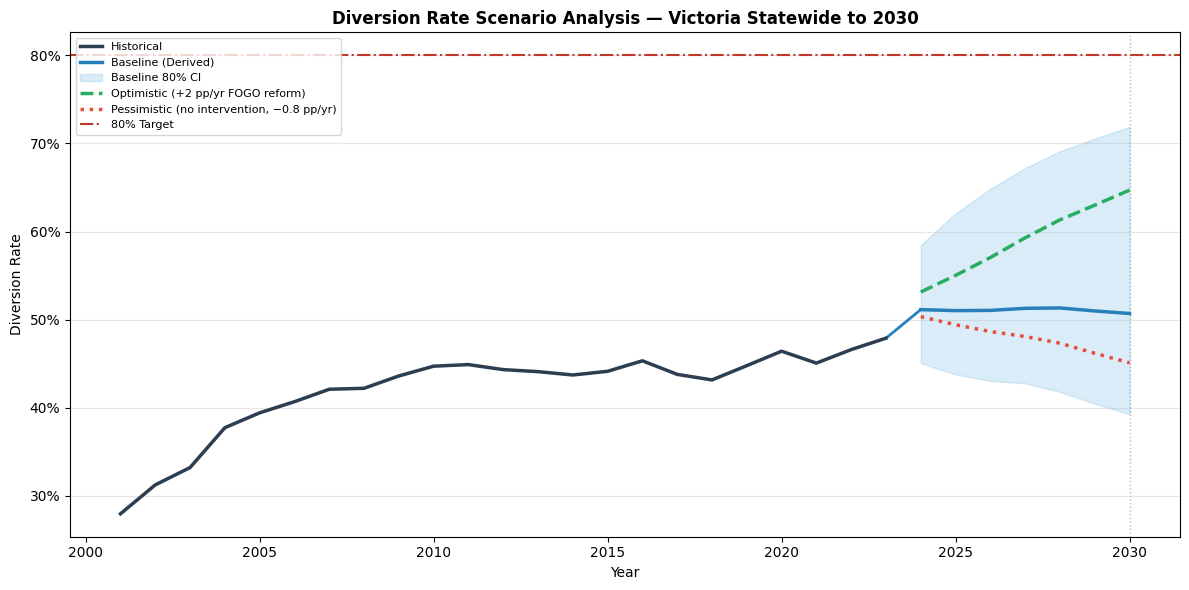


Scenario year-by-year diversion rate forecast:
 Year Baseline Optimistic Pessimistic
 2024    51.1%      53.1%       50.3%
 2025    51.0%      55.0%       49.4%
 2026    51.0%      57.0%       48.6%
 2027    51.3%      59.3%       48.1%
 2028    51.3%      61.3%       47.3%
 2029    51.0%      63.0%       46.2%
 2030    50.7%      64.7%       45.1%


In [13]:
# --- Build scenario arrays ---
div_fwd_sorted = div_fwd.sort_values('index').reset_index(drop=True)
fc_years       = div_fwd_sorted['index'].values.astype(int)
baseline_vals  = div_fwd_sorted['fitted'].values
ci_lo_vals     = div_fwd_sorted['lower_ci'].values
ci_hi_vals     = div_fwd_sorted['upper_ci'].values
n_fc           = len(fc_years)  # should be 7

# Optimistic: +2 pp first year ramping to +14 pp by year 7 (cumulative delta)
opt_boost      = np.linspace(0.02, 0.14, n_fc)   # 2 pp -> 14 pp cumulative above baseline
# Pessimistic: -0.8 pp first year to -5.6 pp cumulative
pess_drag      = np.linspace(0.008, 0.056, n_fc)  # 0.8 pp -> 5.6 pp below baseline

optimistic_vals  = np.clip(baseline_vals + opt_boost,  0, 1)
pessimistic_vals = np.clip(baseline_vals - pess_drag,  0, 1)

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 6))

# Historical
hist_x = div_hist['index'].values
hist_y = div_hist['actual'].values
ax.plot(hist_x, hist_y, color=HIST_COLOR, lw=2.5, label="Historical", zorder=5)

# Join line from last historical to first forecast
last_hist_val = div_hist['actual'].dropna().iloc[-1]
ax.plot([hist_x[-1], fc_years[0]], [last_hist_val, baseline_vals[0]], color=FC_COLOR, lw=2)

# Baseline
ax.plot(fc_years, baseline_vals, color=FC_COLOR, lw=2.5, label="Baseline (Derived)", zorder=4)
ax.fill_between(fc_years, ci_lo_vals, ci_hi_vals, color=CI_COLOR, alpha=0.3, label="Baseline 80% CI")

# Optimistic
ax.plot(fc_years, optimistic_vals, color="#27ae60", lw=2.5, ls="--",
        label="Optimistic (+2 pp/yr FOGO reform)")

# Pessimistic
ax.plot(fc_years, pessimistic_vals, color="#e74c3c", lw=2.5, ls=":",
        label="Pessimistic (no intervention, −0.8 pp/yr)")

# 80% target line
ax.axhline(DIVERSION_TARGET, color="#c0392b", ls="-.", lw=1.5, label="80% Target")
ax.axvline(TARGET_YEAR, color="#7f8c8d", ls=":", lw=1, alpha=0.6)

ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Diversion Rate", fontsize=10)
ax.set_title("Diversion Rate Scenario Analysis — Victoria Statewide to 2030",
             fontweight="bold", fontsize=12)
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "fig_scenario_analysis.png", dpi=150, bbox_inches="tight")
print("Saved fig_scenario_analysis.png")
plt.show()

# --- Scenario table ---
scenario_df = pd.DataFrame({
    "Year":       fc_years,
    "Baseline":   [f"{v:.1%}" for v in baseline_vals],
    "Optimistic": [f"{v:.1%}" for v in optimistic_vals],
    "Pessimistic":[f"{v:.1%}" for v in pessimistic_vals],
})
print("\nScenario year-by-year diversion rate forecast:")
print(scenario_df.to_string(index=False))

### 1.9 Insights

In [14]:
insight_rows = []
for cfg in SERIES_CFG:
    fc_df       = all_fc[cfg['col']]
    hist        = fc_df[~fc_df['is_forecast']]
    fwd         = fc_df[fc_df['is_forecast']]
    last_actual = hist['actual'].dropna().iloc[-1]
    last_row    = fwd.iloc[-1]
    fc_val      = last_row['fitted']
    fc_lo       = last_row['lower_ci']
    fc_hi       = last_row['upper_ci']
    yr          = str(int(last_row['index']))
    change_pct  = (fc_val - last_actual) / last_actual * 100 if last_actual != 0 else 0

    # Three-branch verb: meaningful change only if >1% either direction
    if change_pct > 1:
        verb = "rise"
    elif change_pct < -1:
        verb = "fall"
    else:
        verb = None  # "remain near"

    # CI label varies by series
    if cfg['col'] == 'organics_fogo':
        ci_tag = "80% CI"
    elif cfg['method'] == 'derived':
        ci_tag = "50% CI"
    else:
        ci_tag = "95% CI"

    if cfg['pct']:
        change_pp = (fc_val - last_actual) * 100  # absolute pp change for pct series
        if verb:
            short = f"Forecast to {verb} from {last_actual:.1%} to {fc_val:.1%} by {yr}"
            long_ = (f"{cfg['label']} forecast to {verb} from {last_actual:.1%} to {fc_val:.1%} "
                     f"by {yr} ({change_pp:+.1f} pp). {ci_tag}: {fc_lo:.1%}–{fc_hi:.1%}.")
        else:
            short = f"Forecast to remain near {last_actual:.1%} by {yr}"
            long_ = (f"{cfg['label']} forecast to remain near {last_actual:.1%} by {yr} "
                     f"({change_pp:+.1f} pp). {ci_tag}: {fc_lo:.1%}–{fc_hi:.1%}.")
    else:
        if verb:
            short = f"Forecast to {verb} from {last_actual:.1f} to {fc_val:.1f} {cfg['unit']} by {yr}"
            long_ = (f"{cfg['label']} forecast to {verb} from {last_actual:.1f} to {fc_val:.1f} "
                     f"{cfg['unit']} by {yr} ({change_pct:+.1f}%). {ci_tag}: {fc_lo:.1f}–{fc_hi:.1f}.")
        else:
            short = f"Forecast to remain near {last_actual:.1f} {cfg['unit']} by {yr}"
            long_ = (f"{cfg['label']} forecast to remain near {last_actual:.1f} {cfg['unit']} by {yr} "
                     f"({change_pct:+.1f}%). {ci_tag}: {fc_lo:.1f}–{fc_hi:.1f}.")

    insight_rows.append({"series_name": cfg['label'], "method": cfg['method'],
                         "insight_short": short, "insight_long": long_})

ins_df = pd.DataFrame(insight_rows)
display(ins_df)


,series_name,method,insight_short,insight_long
0,Total Waste (kt),derived,Forecast to rise from 2485.9 to 2623.2 kt by 2030,Total Waste (kt) forecast to rise from 2485.9 ...
1,Garbage Collected (kt),arima,Forecast to rise from 1093.3 to 1105.5 kt by 2030,Garbage Collected (kt) forecast to rise from 1...
2,Recycling Collected (kt),arima,Forecast to rise from 527.3 to 544.1 kt by 2030,Recycling Collected (kt) forecast to rise from...
3,Recycling Recycled (kt),arima,Forecast to fall from 411.5 to 375.2 kt by 2030,Recycling Recycled (kt) forecast to fall from ...
4,Recycling Glass (kt),arima,Forecast to fall from 75.6 to 69.1 kt by 2030,Recycling Glass (kt) forecast to fall from 75....
5,Organics FOGO (kt),arimax,Forecast to rise from 636.7 to 814.0 kt by 2030,Organics FOGO (kt) forecast to rise from 636.7...
6,Organics GO (kt),ets,Forecast to fall from 81.7 to 0.0 kt by 2030,Organics GO (kt) forecast to fall from 81.7 to...
7,Glass Collected (kt),arima,Forecast to fall from 16.5 to 11.7 kt by 2030,Glass Collected (kt) forecast to fall from 16....
8,Hard Waste Collected (kt),arima,Forecast to rise from 130.5 to 148.0 kt by 2030,Hard Waste Collected (kt) forecast to rise fro...
9,Diversion Rate,derived,Forecast to rise from 47.9% to 50.7% by 2030,Diversion Rate forecast to rise from 47.9% to ...


### 1.10 Export → STATEWIDE_DIR

In [15]:
SERIES_CAT_MAP = {
    "total_waste":         ("Total",           "All"),
    "garbage_collected":   ("Garbage",          "Collected"),
    "recycling_collected": ("Recycling",        "Collected"),
    "recycling_recycled":  ("Recycling",        "Recycled"),
    "recycling_glass":     ("Recycling",        "Glass"),
    "organics_fogo":       ("Organics",         "FOGO"),
    "organics_go":         ("Organics",         "GO"),
    "glass_collected":     ("Glass",            "Collected"),
    "hardwaste_collected": ("Hard Waste",       "Collected"),
    "diversion_rate":      ("Diversion Rate",   "All"),
    "kg_per_capita":       ("Waste Per Capita", "All"),
}
proj_rows = []
for cfg in SERIES_CFG:
    _cat, _sub = SERIES_CAT_MAP.get(cfg['col'], (cfg['col'], ""))
    for _, row in all_fc[cfg['col']].iterrows():
        proj_rows.append({
            "start_year":   int(row['index']),
            "category":     _cat,
            "subcategory":  _sub,
            "state":        "Victoria",
            "label":        cfg['label'],
            "unit":         cfg['unit'],
            "method":       cfg['method'],
            "actual":       round(row['actual'],   4) if pd.notna(row['actual'])   else np.nan,
            "fitted":       round(row['fitted'],   4) if pd.notna(row['fitted'])   else np.nan,
            "lower_ci":     round(row['lower_ci'], 4) if pd.notna(row['lower_ci']) else np.nan,
            "upper_ci":     round(row['upper_ci'], 4) if pd.notna(row['upper_ci']) else np.nan,
            "is_forecast":  bool(row['is_forecast']),
            "reliability":  row['reliability'],
            "data_vintage": "Victoria data current through 2023; 2024-2030 are forecast years",
        })
proj_df = pd.DataFrame(proj_rows)[[
    "start_year", "category", "subcategory", "state",
    "label", "unit", "method", "actual", "fitted",
    "lower_ci", "upper_ci", "is_forecast", "reliability", "data_vintage",
]]

# Fill any internal year gaps in historical rows with NaN (e.g. recycling_glass 2021)
def _fill_year_gaps(df):
    parts = []
    # Process in original SERIES_CFG order
    for (cat, sub), grp in df.groupby(['category', 'subcategory'], sort=False):
        hist = grp[~grp['is_forecast']].copy()
        fc   = grp[ grp['is_forecast']].copy()
        if len(hist) > 1:
            yr_min = int(hist['start_year'].min())
            yr_max = int(hist['start_year'].max())
            missing = set(range(yr_min, yr_max + 1)) - set(hist['start_year'].astype(int))
            if missing:
                tmpl = hist.iloc[0].to_dict()
                gap_rows = []
                for yr in sorted(missing):
                    r = tmpl.copy()
                    r['start_year'] = yr
                    r['actual'] = float('nan')
                    r['fitted'] = float('nan')
                    r['lower_ci'] = float('nan')
                    r['upper_ci'] = float('nan')
                    r['is_forecast'] = False
                    gap_rows.append(r)
                hist = pd.concat([hist, pd.DataFrame(gap_rows)],
                                 ignore_index=True).sort_values('start_year')
        parts.append(pd.concat([hist, fc], ignore_index=True))
    return pd.concat(parts, ignore_index=True)

proj_df = _fill_year_gaps(proj_df)
_gap_series = proj_df.groupby(['category','subcategory'])['start_year'].count()
print(f"  Gap-filled rows by series: "
      f"{dict(_gap_series[_gap_series != 30].items())}")
proj_df.to_csv(STATEWIDE_DIR / "forecast_waste_projection.csv", index=False)
print(f"forecast_waste_projection.csv     ({proj_df.shape[0]} rows)")

_sw_eval_df = pd.DataFrame(all_metrics)[[
    "series", "method", "order", "MAE", "RMSE", "MAPE_pct",
    "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability",
]].copy()
_sw_eval_df["data_vintage"] = "Victoria data current through 2023; 2024-2030 are forecast years"
_sw_eval_df.to_csv(STATEWIDE_DIR / "forecast_model_evaluation.csv", index=False)
print(f"forecast_model_evaluation.csv     ({len(all_metrics)} models)")

ins_df.to_csv(STATEWIDE_DIR / "forecast_insights.csv", index=False)
print(f"forecast_insights.csv             ({ins_df.shape[0]} rows)")

scenario_df.to_csv(STATEWIDE_DIR / "forecast_scenario_analysis.csv", index=False)
print(f"forecast_scenario_analysis.csv    ({scenario_df.shape[0]} rows)")

print(f"\nAll statewide exports written to: {STATEWIDE_DIR}")

  Gap-filled rows by series: {('Glass', 'Collected'): 12, ('Organics', 'FOGO'): 28}
forecast_waste_projection.csv     (310 rows)
forecast_model_evaluation.csv     (11 models)
forecast_insights.csv             (11 rows)
forecast_scenario_analysis.csv    (7 rows)

All statewide exports written to: Dataset\Gold\statewide


---
# Part 2 — LGA Council Breakdown
**Source:** `Dataset/Cleaned/cleaned_vlgas.csv` — all 79 Victorian councils  
**Task:** Forecast diversion rate per council to 2030 using fast ARIMA  
**Filter:** Only councils with ≥ 10 years of data

### 2.1 Load & Derive Per-Council Diversion Rates

In [16]:
df_lga = pd.read_csv(ROOT / "Dataset" / "Cleaned" / "cleaned_vlgas.csv")

df_lga['hardwaste_recovered'] = (
    df_lga['hardwaste_collected_tonnes'].fillna(0)
    - df_lga['hardwaste_disposed_tonnes'].fillna(0)
).clip(lower=0)

all_cols_lga = ['garbage_collected_total_tonnes', 'dropoff_garbage_collected_tonnes',
                'kerbside_recycling_total_collected_tonnes', 'dropoff_recycling_collected_tonnes',
                'kerbside_organics_collected_tonnes', 'kerbside_glass_total_collected_tonnes',
                'hardwaste_collected_tonnes']
df_lga['_total']   = df_lga[all_cols_lga].fillna(0).sum(axis=1)
df_lga['_diverted'] = (df_lga['kerbside_recycling_total_recycled_tonnes'].fillna(0)
                        + df_lga['kerbside_organics_processed_tonnes'].fillna(0)
                        + df_lga['hardwaste_recovered'])

lga_annual = (df_lga.groupby(['council', 'start_year'])
              .agg(_total=('_total','sum'), _diverted=('_diverted','sum'))
              .reset_index())
lga_annual['diversion_rate'] = (lga_annual['_diverted'] /
                                 lga_annual['_total'].replace(0, np.nan)).round(4)

# Count years per council
lga_counts = lga_annual.groupby('council')['start_year'].count().rename('n_years')
eligible   = lga_counts[lga_counts >= 10].index.tolist()

print(f"Total councils: {lga_annual['council'].nunique()}")
print(f"Eligible (>= 10 years): {len(eligible)}")
print("Year range:", lga_annual['start_year'].min(), "–", lga_annual['start_year'].max())

Total councils: 79
Eligible (>= 10 years): 79
Year range: 2001 – 2023


### 2.2 Forecast Loop (ARIMA per Council)

In [17]:
lga_results = []
lga_errors  = []
last_yr_lga = int(lga_annual['start_year'].max())
horizon_lga = TARGET_YEAR - last_yr_lga

print(f"Forecasting {len(eligible)} councils → {TARGET_YEAR}  (horizon={horizon_lga} years)")
print("-" * 60)

for i, council in enumerate(sorted(eligible)):
    if i % 10 == 0:
        print(f"  [{i+1}/{len(eligible)}] Processing: {council}")
    try:
        sub = (lga_annual[lga_annual['council'] == council]
               .sort_values('start_year')
               .set_index('start_year')['diversion_rate']
               .dropna())
        if len(sub) < 10:
            lga_errors.append((council, 'insufficient data after dropna'))
            continue

        vals = sub.values.astype(float)
        auto = pm.auto_arima(vals, seasonal=False, m=1, stepwise=True,
                             information_criterion="aic", suppress_warnings=True,
                             error_action="ignore",
                             max_p=2, max_q=2, max_d=1, n_fits=10)
        order = auto.order

        full_fit = SARIMAX(vals, order=order, seasonal_order=(0,0,0,0),
                           enforce_stationarity=False, enforce_invertibility=False
                           ).fit(disp=False)
        fc_vals = np.array(full_fit.forecast(steps=horizon_lga)).flatten()
        fc_vals = np.clip(fc_vals, 0, 1)

        last_actual = float(sub.iloc[-1])
        recent_mean = float(sub.tail(5).mean())
        implausible_collapse = (last_actual > 0.10) and (fc_vals[-1] < 0.5 * last_actual)
        if implausible_collapse:
            weights  = np.linspace(0.85, 0.5, len(fc_vals))
            fc_vals  = weights * last_actual + (1 - weights) * recent_mean
            fc_vals  = np.clip(fc_vals, 0, 1)
            fallback_used = True
        else:
            fallback_used = False

        fc_2030 = float(fc_vals[-1])

        lga_results.append({
            "council":       council,
            "n_years":       len(sub),
            "last_year":     int(sub.index[-1]),
            "last_actual":   round(last_actual, 4),
            "order":         str(order),
            "fallback_used": fallback_used,
            "fc_2030":       round(fc_2030, 4),
            **{f"fc_{last_yr_lga + j + 1}": round(float(fc_vals[j]), 4)
               for j in range(horizon_lga)},
        })
    except Exception as e:
        lga_errors.append((council, str(e)))

print(f"\nCompleted: {len(lga_results)} councils  |  Errors/skipped: {len(lga_errors)}")
n_fallback = sum(1 for r in lga_results if r.get('fallback_used'))
print(f"Fallback (damped persistence) used: {n_fallback} councils")
if lga_errors:
    print("Errors:", [(c, e[:60]) for c, e in lga_errors[:5]])

Forecasting 79 councils → 2030  (horizon=7 years)
------------------------------------------------------------
  [1/79] Processing: Alpine Shire Council


  [11/79] Processing: Buloke Shire Council


  [21/79] Processing: Gannawarra Shire Council


  [31/79] Processing: Hobsons Bay City Council


  [41/79] Processing: Mansfield Shire Council


  [51/79] Processing: Moonee Valley City Council


  [61/79] Processing: Queenscliffe Borough Council


  [71/79] Processing: Wellington Shire Council



Completed: 79 councils  |  Errors/skipped: 0
Fallback (damped persistence) used: 15 councils


### 2.3 Rankings Table (All Councils, Sorted by 2030 Forecast)

In [18]:
lga_fc_df = pd.DataFrame(lga_results).sort_values('fc_2030', ascending=True).reset_index(drop=True)
lga_fc_df.index = lga_fc_df.index + 1  # 1-based rank
lga_fc_df.index.name = 'rank_2030'

display_cols = ['council', 'n_years', 'last_actual', 'order', 'fc_2030']
print(f"Full rankings ({len(lga_fc_df)} councils):")
display(lga_fc_df[display_cols].style.format({'last_actual': '{:.1%}', 'fc_2030': '{:.1%}'}))

Full rankings (79 councils):


,council,n_years,last_actual,order,fc_2030
rank_2030,,,,,
1,Hindmarsh Shire Council,23,8.9%,"(0, 0, 0)",0.0%
2,West Wimmera Shire Council,23,10.8%,"(1, 0, 0)",7.1%
3,Yarriambiack Shire Council,23,14.3%,"(1, 0, 0)",9.9%
4,Loddon Shire Council,23,22.7%,"(1, 0, 0)",12.6%
5,Buloke Shire Council,23,19.4%,"(0, 0, 0)",18.1%
6,Mansfield Shire Council,22,22.8%,"(0, 1, 1)",20.3%
7,Hepburn Shire Council,23,34.5%,"(1, 0, 0)",21.5%
8,Glenelg Shire Council,23,21.7%,"(0, 1, 0)",21.7%
9,Towong Shire Council,23,22.3%,"(1, 0, 0)",21.8%


### 2.4 Chart — Top 10 & Bottom 10 Councils by 2030 Diversion Rate

Saved fig_lga_diversion_ranking.png


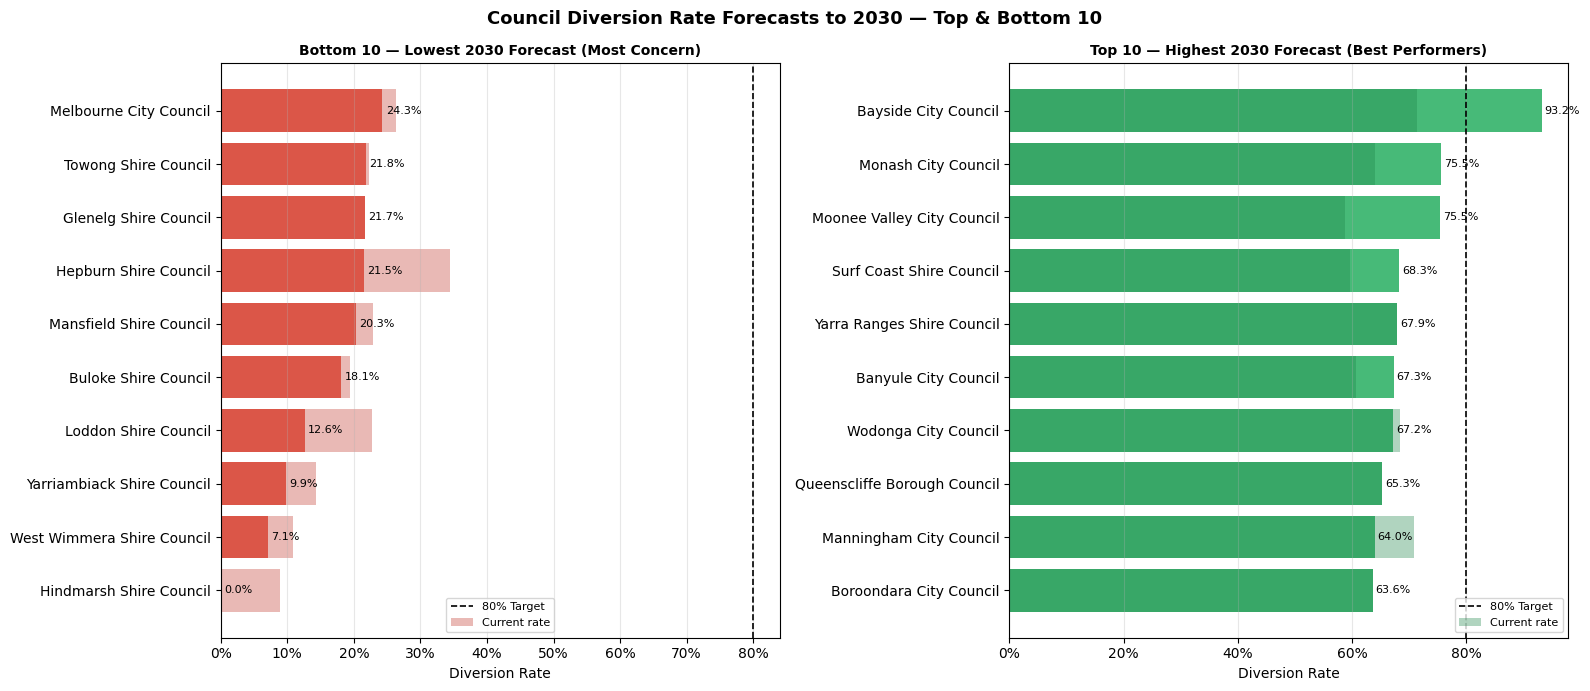

In [19]:
bottom10 = lga_fc_df.head(10).copy()   # lowest (worst) diversion
top10    = lga_fc_df.tail(10).copy()   # highest (best) diversion

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(f"Council Diversion Rate Forecasts to {TARGET_YEAR} — Top & Bottom 10",
             fontweight="bold", fontsize=13)

# Bottom 10 (worst performers)
ax1.barh(bottom10['council'], bottom10['fc_2030'], color='#e74c3c', alpha=0.85)
ax1.barh(bottom10['council'], bottom10['last_actual'], color='#c0392b', alpha=0.35, label='Current rate')
ax1.axvline(DIVERSION_TARGET, color='black', ls='--', lw=1.2, label='80% Target')
ax1.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax1.set_title("Bottom 10 — Lowest 2030 Forecast (Most Concern)", fontsize=10, fontweight='bold')
ax1.set_xlabel("Diversion Rate")
ax1.legend(fontsize=8)
ax1.grid(axis='x', alpha=0.3)

# Add value labels
for i, (_, row) in enumerate(bottom10.iterrows()):
    ax1.text(row['fc_2030'] + 0.005, i, f"{row['fc_2030']:.1%}", va='center', fontsize=8)

# Top 10 (best performers)
ax2.barh(top10['council'], top10['fc_2030'], color='#27ae60', alpha=0.85)
ax2.barh(top10['council'], top10['last_actual'], color='#1e8449', alpha=0.35, label='Current rate')
ax2.axvline(DIVERSION_TARGET, color='black', ls='--', lw=1.2, label='80% Target')
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax2.set_title("Top 10 — Highest 2030 Forecast (Best Performers)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Diversion Rate")
ax2.legend(fontsize=8)
ax2.grid(axis='x', alpha=0.3)

for i, (_, row) in enumerate(top10.iterrows()):
    ax2.text(row['fc_2030'] + 0.005, i, f"{row['fc_2030']:.1%}", va='center', fontsize=8)

fig.tight_layout()
fig.savefig(CHARTS_DIR / "fig_lga_diversion_ranking.png", dpi=150, bbox_inches="tight")
print("Saved fig_lga_diversion_ranking.png")
plt.show()

### 2.5 Export → LGA_DIR

In [20]:
# Reset index so rank becomes a column
lga_export = lga_fc_df.reset_index()
lga_export.to_csv(LGA_DIR / "lga_diversion_forecast.csv", index=False)
print(f"lga_diversion_forecast.csv  ({lga_export.shape[0]} councils, {lga_export.shape[1]} cols)")
print(f"Written to: {LGA_DIR}")

lga_diversion_forecast.csv  (79 councils, 14 cols)
Written to: Dataset\Gold\statewide\lga


---
# Part 3 — City of Melbourne Case Study (ARIMA → 2030)
**Source:** `Dataset/Raw/waste-collected-per-month.xlsx` — City of Melbourne only  
**Purpose:** Shows Melbourne is significantly underperforming the statewide average — the policy hook  
**History:** 2010–2019 (10 years, aggregated from monthly)

| Category | Available? |
|---|---|
| Total waste, Garbage, Recycling collected, Organics GO, Hard waste, Diversion rate | ✅ |
| Recycling recycled, FOGO, Glass, Waste per capita | ❌ Not in source data |

### 3.1 Load & Derive Annual Series

In [21]:
MELB_SERIES_CFG = [
    dict(col="total_waste",         label="Total Waste (kt)",         unit="kt", pct=False, method="derived"),
    dict(col="garbage",             label="Garbage Collected (kt)",   unit="kt", pct=False),
    dict(col="recycling_collected", label="Recycling Collected (kt)", unit="kt", pct=False),
    dict(col="organics_go",         label="Organics GO (kt)",         unit="kt", pct=False),
    dict(col="hardwaste",           label="Hard Waste (kt)",          unit="kt", pct=False),
    dict(col="diversion_rate",      label="Diversion Rate",           unit="%",  pct=True,  method="derived"),
]


def load_melb_annual() -> pd.DataFrame:
    # Reads from the cleaned CSV produced by data_cleaning.ipynb (not the raw xlsx),
    # keeping the data layer consistent with the VLGAS and VWPPM pipelines.
    df = pd.read_csv(ROOT / "Dataset" / "Cleaned" / "cleaned_melbourne.csv",
                     parse_dates=['date'])
    df = df[df['year'].between(2010, 2019)].copy()

    df['_garbage']   = df['residential'] + df['public_litter_bins'] + df['dumped_rubbish'] + df['street_sweepings']
    df['_recycling'] = df['commingled_recycling'] + df['cardboard']
    df['_organics']  = df['green_waste']
    df['_hardwaste'] = df['hardwaste_total']
    df['_total']     = df['_garbage'] + df['_recycling'] + df['_organics'] + df['_hardwaste']
    df['_diverted']  = df['_recycling'] + df['hardwaste_recovered'] + df['_organics']

    agg = df.groupby('year').agg(
        _total    =('_total',    'sum'), _garbage  =('_garbage',  'sum'),
        _recycling=('_recycling','sum'), _organics =('_organics', 'sum'),
        _hardwaste=('_hardwaste','sum'), _diverted =('_diverted', 'sum'),
        _hw_rec   =('hardwaste_recovered', 'sum'),
    ).reset_index()

    melb = pd.DataFrame(index=agg['year'], data={
        'total_waste':         (agg['_total']     / 1_000).round(3).values,
        'garbage':             (agg['_garbage']   / 1_000).round(3).values,
        'recycling_collected': (agg['_recycling'] / 1_000).round(3).values,
        'organics_go':         (agg['_organics']  / 1_000).round(3).values,
        'hardwaste':           (agg['_hardwaste'] / 1_000).round(3).values,
        'hardwaste_recovered': (agg['_hw_rec']    / 1_000).round(3).values,
        'diversion_rate':      (agg['_diverted']  / agg['_total']).round(4).values,
    })
    melb.index.name = 'year'
    print(f"City of Melbourne — {len(melb)} years ({melb.index.min()}–{melb.index.max()})")
    return melb


melb_annual = load_melb_annual()
display(melb_annual)

City of Melbourne — 10 years (2010–2019)


,total_waste,garbage,recycling_collected,organics_go,hardwaste,hardwaste_recovered,diversion_rate
year,,,,,,,
2010,40.965,31.896,8.707,0.046,0.316,0.000,0.2137
2011,40.646,31.353,8.856,0.058,0.379,0.000,0.2193
2012,40.081,31.417,8.185,0.052,0.426,0.000,0.2055
2013,42.138,32.793,8.741,0.049,0.556,0.000,0.2086
2014,44.236,34.582,8.756,0.051,0.846,0.000,0.1991
2015,45.276,34.413,9.782,0.052,1.030,0.121,0.2199
2016,47.445,35.751,10.789,0.062,0.844,0.303,0.2351
2017,49.778,37.174,11.565,0.107,0.933,0.219,0.2389
2018,50.608,37.630,11.899,0.115,0.964,0.200,0.2413


### 3.2 Run Forecasts

In [22]:
melb_fc, melb_metrics = {}, []
melb_last    = int(melb_annual.index.max())
melb_horizon = TARGET_YEAR - melb_last

print("=" * 65)
print(f"  CITY OF MELBOURNE — ARIMA ({melb_annual.index.min()}–{melb_last} -> {TARGET_YEAR})")
print("=" * 65)

for cfg in MELB_SERIES_CFG:
    if cfg.get('method') == 'derived':
        continue
    fc_df, metrics = fit_arima(
        series        =melb_annual[cfg['col']],
        label         =cfg['label'],
        forecast_steps=melb_horizon,
        test_size     =2,
    )
    metrics['unit']   = cfg['unit']
    metrics['method'] = cfg.get('method', 'arima')
    melb_metrics.append(metrics)
    melb_fc[cfg['col']] = fc_df

# Derive total_waste from 4 Melbourne components
MELB_TW_COMPONENTS = ['garbage', 'recycling_collected', 'organics_go', 'hardwaste']
melb_fc['total_waste'] = derive_total_from_components(
    melb_fc, MELB_TW_COMPONENTS, label='Total Waste (kt)')

# Insert derived metric row at front of melb_metrics
melb_metrics.insert(0, {
    'series': 'Total Waste (kt)', 'method': 'derived',
    'order': 'sum(4 components)',
    'MAE': float('nan'), 'RMSE': float('nan'), 'MAPE_pct': float('nan'),
    'AIC': float('nan'), 'test_size': float('nan'), 'reliability': 'derived',
    'n_years_history': float('nan'), 'log_transform': False,
    'ci_alpha_used': float('nan'), 'unit': 'kt',
})

print(f"\nMelbourne Total Waste (derived) — 2030 forecast: {melb_fc['total_waste'][melb_fc['total_waste']['is_forecast']]['fitted'].values[-1]:.1f} kt")
comp_sum_2030 = sum(
    melb_fc[c][melb_fc[c]['is_forecast']]['fitted'].values[-1]
    for c in MELB_TW_COMPONENTS)
print(f"Melbourne component sum check:  {comp_sum_2030:.1f} kt (diff: {abs(melb_fc['total_waste'][melb_fc['total_waste']['is_forecast']]['fitted'].values[-1] - comp_sum_2030):.4f} kt)")

# Derive Melbourne Diversion Rate
# Formula: (recycling_collected + organics_go + hardwaste_recovered) / total_waste
# Melbourne uses collected organics directly (no processing-loss correction needed).
# hardwaste_recovered now available in melb_annual; last actual used for forecast.
_melb_hw_rec_by_yr = dict(zip(melb_annual.index, melb_annual['hardwaste_recovered']))
_melb_hw_rec_last  = float(melb_annual['hardwaste_recovered'].dropna().iloc[-1])
print(f"\n  Melbourne hardwaste_recovered (last actual): {_melb_hw_rec_last:.3f} kt")
print(f"  (Melbourne organics = green_waste collected; no processing rate applied)")

MELB_DIV_COMPS = ['recycling_collected', 'organics_go']
melb_div_rows = []
for _, tw_row in melb_fc['total_waste'].iterrows():
    yr    = int(tw_row['index'])
    is_fc = bool(tw_row['is_forecast'])
    tw_f  = float(tw_row['fitted']) if pd.notna(tw_row['fitted']) else np.nan
    hw_rec = _melb_hw_rec_last if is_fc else (_melb_hw_rec_by_yr.get(yr, _melb_hw_rec_last) or _melb_hw_rec_last)
    num_f, num_lo, num_hi = hw_rec, hw_rec, hw_rec
    for col in MELB_DIV_COMPS:
        cr = melb_fc[col][melb_fc[col]['index'] == yr]
        if len(cr) == 0:
            continue
        f  = float(cr['fitted'].iloc[0])   if pd.notna(cr['fitted'].iloc[0])   else 0.0
        lo = float(cr['lower_ci'].iloc[0]) if pd.notna(cr['lower_ci'].iloc[0]) else f
        hi = float(cr['upper_ci'].iloc[0]) if pd.notna(cr['upper_ci'].iloc[0]) else f
        num_f  += f
        num_lo += lo
        num_hi += hi
    if pd.notna(tw_f) and tw_f > 0:
        div_fit = num_f  / tw_f
        div_lo  = max(0.0, num_lo / tw_f) if is_fc else np.nan
        div_hi  = min(1.0, num_hi / tw_f) if is_fc else np.nan
    else:
        div_fit = div_lo = div_hi = np.nan
    actual_div = melb_annual.loc[yr, 'diversion_rate'] if (not is_fc and yr in melb_annual.index) else np.nan
    melb_div_rows.append({'index': yr, 'actual': actual_div, 'fitted': div_fit,
                          'lower_ci': div_lo, 'upper_ci': div_hi,
                          'is_forecast': is_fc, 'series': 'diversion_rate', 'reliability': 'derived'})
melb_fc['diversion_rate'] = pd.DataFrame(melb_div_rows)

# Melbourne historical reconciliation
print('\n  Melbourne Diversion Rate — historical reconciliation:')
print(f'  {"Year":>5}  {"Actual":>8}  {"Derived":>8}  {"Diff":>8}')
_melb_max_diff = 0.0
for r in melb_div_rows:
    if r['is_forecast'] or pd.isna(r['actual']):
        continue
    diff = abs(r['actual'] - r['fitted']) if pd.notna(r['fitted']) else np.nan
    flag = '  ***' if pd.notna(diff) and diff > 0.005 else ''
    print(f'  {r["index"]:>5}  {r["actual"]:>8.4f}  {r["fitted"]:>8.4f}  {diff:>8.4f}{flag}')
    if pd.notna(diff):
        _melb_max_diff = max(_melb_max_diff, diff)
print(f'  Max diff: {_melb_max_diff:.4f}  {"OK" if _melb_max_diff < 0.005 else "WARNING >0.005"}')

# Add Melbourne derived diversion rate metric
melb_metrics.append({
    'series': 'Diversion Rate', 'method': 'derived',
    'order': '(recycling_collected + organics_go) / total_waste',
    'MAE': float('nan'), 'RMSE': float('nan'), 'MAPE_pct': float('nan'),
    'AIC': float('nan'), 'test_size': float('nan'), 'reliability': 'derived',
    'n_years_history': float('nan'), 'log_transform': False,
    'ci_alpha_used': float('nan'), 'unit': '%',
})

  CITY OF MELBOURNE — ARIMA (2010–2019 -> 2030)

  [Garbage Collected (kt)]
    train=8  test=2  horizon=11  reliability=medium (n=10)


    Best order: ARIMA(2, 0, 0)  AIC=31.67
    Test set evaluation:
    MAE  = 1.0944
    RMSE = 1.1912
    MAPE = 2.74%
    CV MAE=0.5308  CV RMSE=0.5308  (1 folds)

  [Recycling Collected (kt)]
    train=8  test=2  horizon=11  reliability=medium (n=10)


    Best order: ARIMA(1, 0, 0)  AIC=23.88
    Test set evaluation:
    MAE  = 2.0134
    RMSE = 2.7075
    MAPE = 22.48%
    CV MAE=0.557  CV RMSE=0.557  (2 folds)

  [Organics GO (kt)]
    train=8  test=2  horizon=11  reliability=medium (n=10)


    Best order: ARIMA(0, 0, 0)  AIC=-37.13
    Test set evaluation:
    MAE  = 0.0509
    RMSE = 0.0510
    MAPE = 45.25%
    CV MAE=0.0737  CV RMSE=0.0737  (3 folds)

  [Hard Waste (kt)]
    train=8  test=2  horizon=11  reliability=medium (n=10)


    Best order: ARIMA(1, 0, 0)  AIC=0.16
    Test set evaluation:
    MAE  = 0.0656
    RMSE = 0.0667
    MAPE = 6.05%
    CV MAE=0.2464  CV RMSE=0.2464  (2 folds)

Melbourne Total Waste (derived) — 2030 forecast: 69.9 kt
Melbourne component sum check:  69.9 kt (diff: 0.0000 kt)

  Melbourne hardwaste_recovered (last actual): 0.320 kt
  (Melbourne organics = green_waste collected; no processing rate applied)

  Melbourne Diversion Rate — historical reconciliation:
   Year    Actual   Derived      Diff
   2010    0.2137       nan       nan
   2011    0.2193       nan       nan
   2012    0.2055    0.2187    0.0132  ***
   2013    0.2086    0.2062    0.0024
   2014    0.1991    0.2103    0.0112  ***
   2015    0.2199    0.1965    0.0234  ***
   2016    0.2351    0.2159    0.0192  ***
   2017    0.2389    0.2266    0.0123  ***
   2018    0.2413    0.2310    0.0103  ***
   2019    0.1815    0.2349    0.0534  ***
  Max diff: 0.0534  WARNING >0.005


### 3.3 Melbourne vs Statewide — Policy Gap

,series,order,MAE,RMSE,MAPE_pct,cv_mae_mean,cv_rmse_mean,AIC,n_years_history,reliability
0,Total Waste (kt),sum(4 components),NaN,NaN,NaN,NaN,NaN,NaN,NaN,derived
1,Garbage Collected (kt),"(2, 0, 0)",1.0944,1.1912,2.74,0.5308,0.5308,31.67,10.0,medium
2,Recycling Collected (kt),"(1, 0, 0)",2.0134,2.7075,22.48,0.5570,0.5570,23.88,10.0,medium
3,Organics GO (kt),"(0, 0, 0)",0.0509,0.0510,45.25,0.0737,0.0737,-37.13,10.0,medium
4,Hard Waste (kt),"(1, 0, 0)",0.0656,0.0667,6.05,0.2464,0.2464,0.16,10.0,medium
5,Diversion Rate,(recycling_collected + organics_go) / total_waste,NaN,NaN,NaN,NaN,NaN,NaN,NaN,derived


Saved fig7_melb_model_evaluation.png


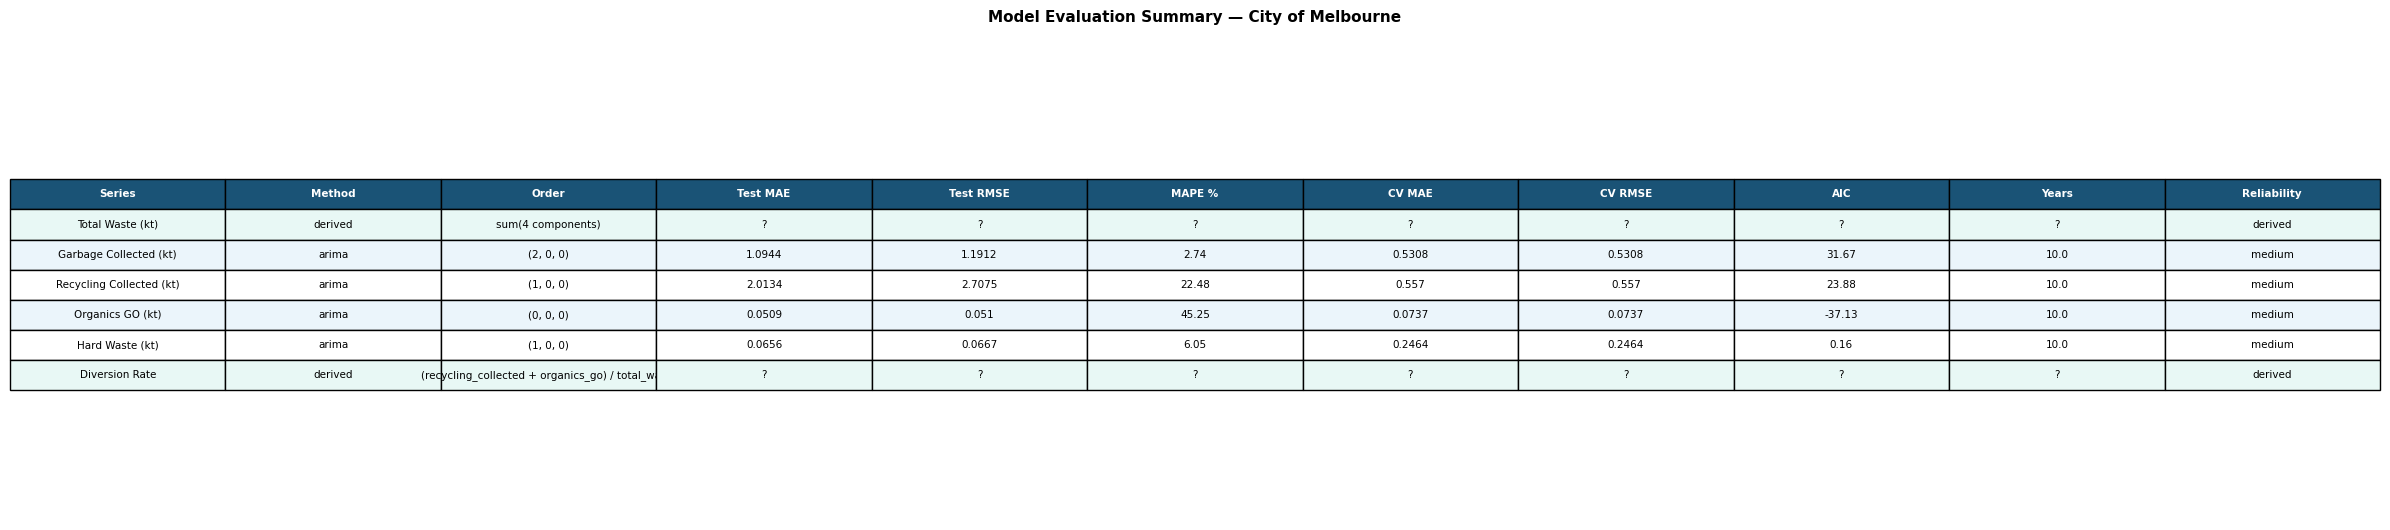

In [23]:
# Melbourne evaluation table
display(pd.DataFrame(melb_metrics)[[
    "series", "order", "MAE", "RMSE", "MAPE_pct",
    "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability",
]])

# Melbourne model evaluation figure
_mcols  = ["series", "method", "order", "MAE", "RMSE", "MAPE_pct",
           "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability"]
_mlbls  = ["Series", "Method", "Order", "Test MAE", "Test RMSE", "MAPE %",
           "CV MAE", "CV RMSE", "AIC", "Years", "Reliability"]
_mdf    = pd.DataFrame(melb_metrics).fillna("?")
_mdata  = _mdf[_mcols].values.tolist()

mfig, max_ = plt.subplots(figsize=(24, len(_mdata) * 0.65 + 1.5))
max_.axis("off")
mtable = max_.table(cellText=_mdata, colLabels=_mlbls, loc="center", cellLoc="center")
mtable.auto_set_font_size(False)
mtable.set_fontsize(7.5)
mtable.scale(1, 1.6)
for j in range(len(_mlbls)):
    mtable[(0, j)].set_facecolor("#1a5376")
    mtable[(0, j)].get_text().set_color("white")
    mtable[(0, j)].get_text().set_fontweight("bold")
for i in range(1, len(_mdata) + 1):
    method_val = _mdata[i - 1][1]
    bg = "#e8f8f5" if method_val == "derived" else ("#ebf5fb" if i % 2 == 0 else "white")
    for j in range(len(_mlbls)):
        mtable[(i, j)].set_facecolor(bg)
max_.set_title("Model Evaluation Summary — City of Melbourne",
              fontweight="bold", fontsize=11, pad=20)
mfig.tight_layout()
mfig.savefig(CHARTS_DIR / "fig7_melb_model_evaluation.png", dpi=150, bbox_inches="tight")
print("Saved fig7_melb_model_evaluation.png")
plt.show()

### 3.3b Forecast Charts

> **Data vintage:** City of Melbourne waste data ends in 2019 (raw file covers April 2009 – March 2020; annual aggregates use 2010–2019 only). Years 2020–2030 are **out-of-sample forecasts**. Post-COVID operational changes and any FOGO service expansions after 2019 are not captured.

Saved fig5_forecast_melb_annual.png


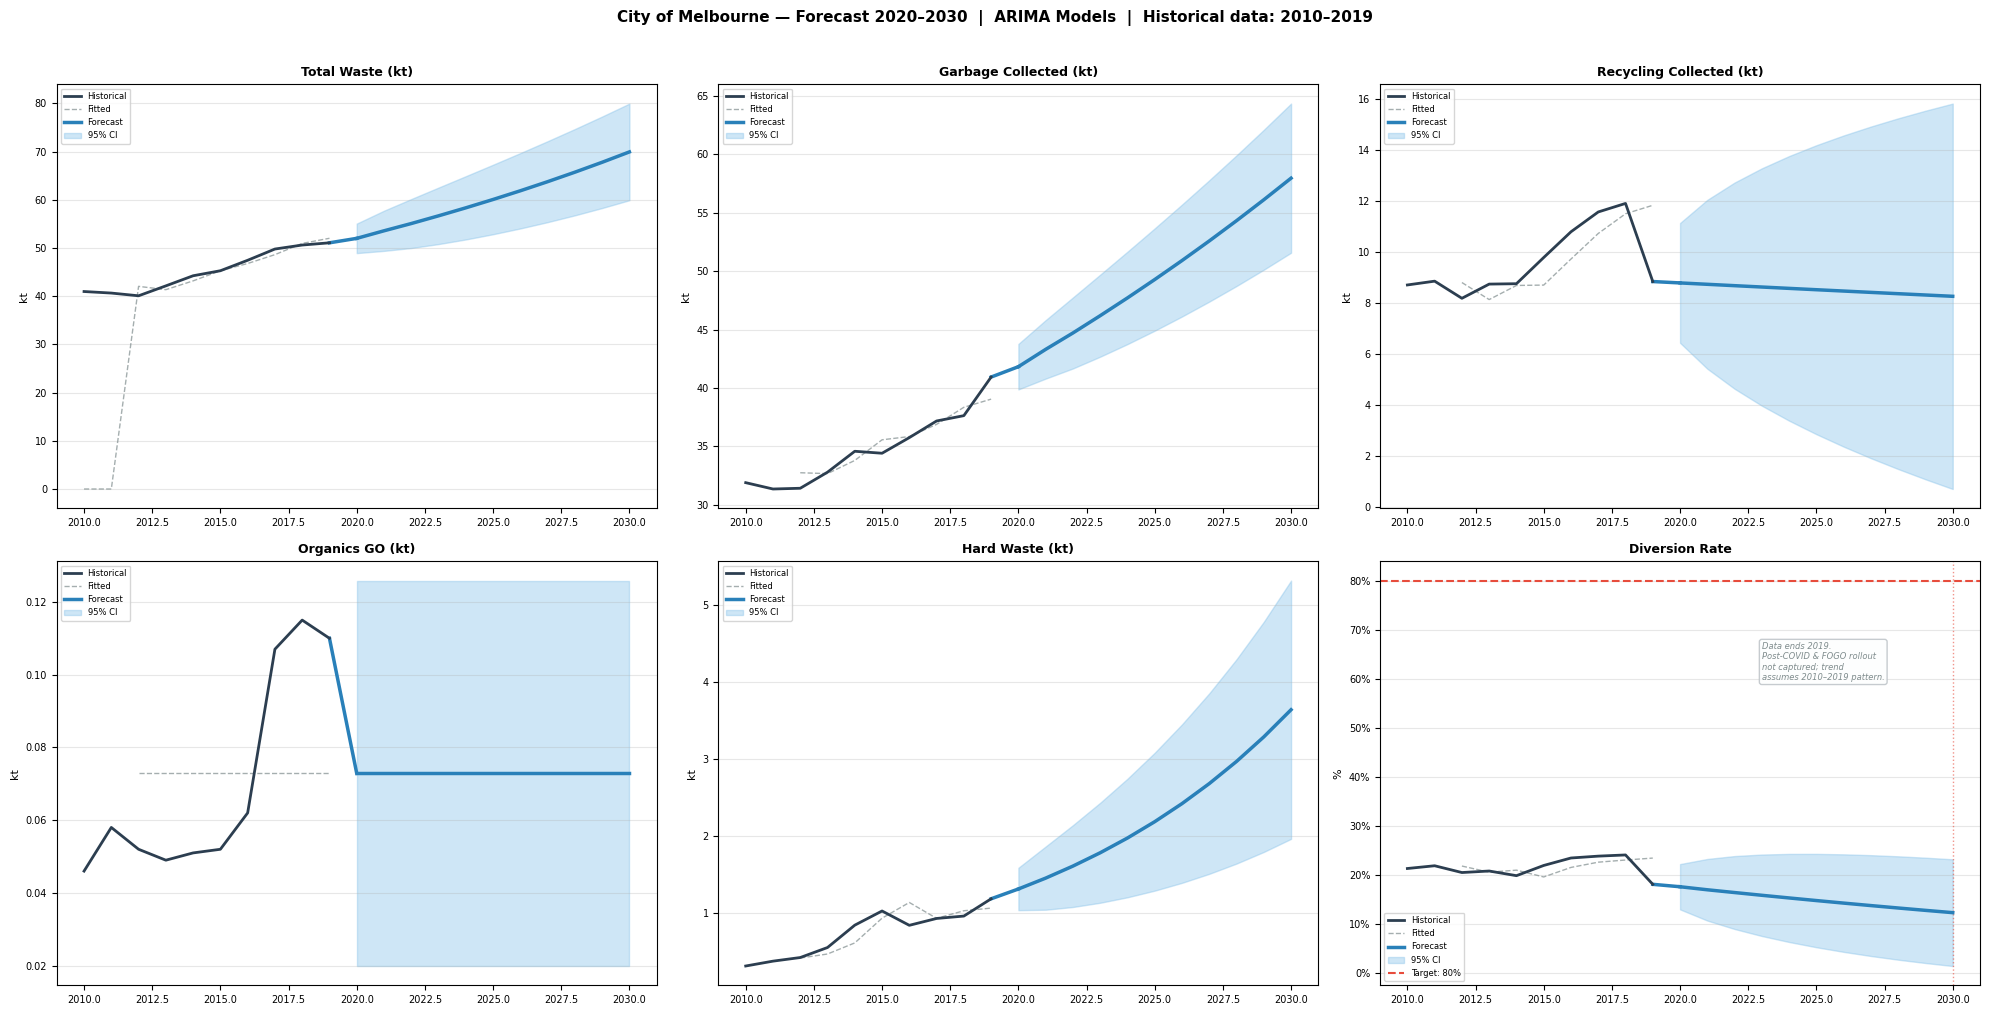

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle(f"City of Melbourne — Forecast 2020–{TARGET_YEAR}  |  ARIMA Models  |  Historical data: 2010–2019",
             fontsize=11, fontweight="bold", y=1.01)
for ax, cfg in zip(axes.flat, MELB_SERIES_CFG):
    target = DIVERSION_TARGET if cfg['col'] == 'diversion_rate' else None
    plot_series(ax, melb_fc[cfg['col']], cfg['unit'], cfg['label'], pct=cfg['pct'], target=target)
# Data-vintage annotation on the diversion rate panel (last panel, index 5 in 2x3 grid)
_div_ax = list(axes.flat)[5]
_div_ax.annotate(
    "Data ends 2019.\nPost-COVID & FOGO rollout\nnot captured; trend\nassumes 2010\u20132019 pattern.",
    xy=(2023, _div_ax.get_ylim()[0] + (_div_ax.get_ylim()[1] - _div_ax.get_ylim()[0]) * 0.72),
    fontsize=6, color='#7f8c8d', style='italic',
    bbox=dict(boxstyle='round,pad=0.3', fc='#fdfefe', alpha=0.85, ec='#bdc3c7'),
)

fig.tight_layout()
fig.savefig(CHARTS_DIR / "fig5_forecast_melb_annual.png", dpi=150, bbox_inches="tight")
print("Saved fig5_forecast_melb_annual.png")
plt.show()

### 3.3c Melbourne vs Statewide Gap

In [25]:
m_div_fwd  = melb_fc['diversion_rate'][melb_fc['diversion_rate']['is_forecast']]
m_div_hist = melb_fc['diversion_rate'][~melb_fc['diversion_rate']['is_forecast']]
m_latest   = m_div_hist['actual'].dropna().iloc[-1]
m_fc_2030  = m_div_fwd[m_div_fwd['index'] == TARGET_YEAR].iloc[0]['fitted']

s_div_fwd  = all_fc['diversion_rate'][all_fc['diversion_rate']['is_forecast']]
s_div_hist = all_fc['diversion_rate'][~all_fc['diversion_rate']['is_forecast']]
s_latest   = s_div_hist['actual'].dropna().iloc[-1]
s_fc_2030  = s_div_fwd[s_div_fwd['index'] == TARGET_YEAR].iloc[0]['fitted']

print("=" * 65)
print("  DIVERSION RATE — MELBOURNE vs STATEWIDE")
print("=" * 65)
print(f"  {'':30} {'Statewide':>12}  {'Melbourne':>12}")
print(f"  {'Latest actual rate':30} {s_latest:>12.1%}  {m_latest:>12.1%}")
print(f"  {'Forecast 2030':30} {s_fc_2030:>12.1%}  {m_fc_2030:>12.1%}")
print(f"  {'Gap from 80% target':30} {DIVERSION_TARGET-s_fc_2030:>12.1%}  {DIVERSION_TARGET-m_fc_2030:>12.1%}")
print()
print(f"  Melbourne is currently {(s_latest - m_latest)*100:.1f} pp BELOW the statewide average.")
print(f"  By 2030, Melbourne is forecast to be {(s_fc_2030 - m_fc_2030)*100:.1f} pp below statewide.")
print()
print("  Melbourne year-by-year diversion forecast:")
for _, row in m_div_fwd.sort_values('index').iterrows():
    yr  = int(row['index'])
    val = row['fitted']
    print(f"    {yr}: {val:.1%}  {'#' * int(val * 20)}")

print()
print("=" * 65)
print("  INTERPRETING MELBOURNE'S DECLINING DIVERSION TRAJECTORY")
print("=" * 65)
print("""
  City of Melbourne is a single council covering the CBD core only —
  it is NOT representative of the ~30 councils that make up metropolitan
  Melbourne — and has a fundamentally
  different waste mix from the Victorian statewide average:
    - Minimal kerbside organics (no FOGO service until very recently)
    - High proportion of commercial/apartment garbage
    - Lower hard-waste and recycling volumes per capita

  A declining diversion rate (forecast ~15% by 2030) is therefore
  directionally plausible and does NOT indicate a modelling error.
  The statewide rate rising while Melbourne's falls reflects the
  roll-out of FOGO and organics programs concentrated in outer
  suburban and regional councils, not the CBD core.

  Reliability is 'medium' (10 years of history, 2010-2019).
  The Melbourne model should be read as indicative only.
""")


  DIVERSION RATE — MELBOURNE vs STATEWIDE
                                    Statewide     Melbourne
  Latest actual rate                    47.9%         18.1%
  Forecast 2030                         50.7%         12.4%
  Gap from 80% target                   29.3%         67.6%

  Melbourne is currently 29.8 pp BELOW the statewide average.
  By 2030, Melbourne is forecast to be 38.3 pp below statewide.

  Melbourne year-by-year diversion forecast:
    2020: 17.7%  ###
    2021: 17.0%  ###
    2022: 16.5%  ###
    2023: 15.9%  ###
    2024: 15.4%  ###
    2025: 14.8%  ##
    2026: 14.3%  ##
    2027: 13.8%  ##
    2028: 13.3%  ##
    2029: 12.8%  ##
    2030: 12.4%  ##

  INTERPRETING MELBOURNE'S DECLINING DIVERSION TRAJECTORY

  City of Melbourne is a single council covering the CBD core only —
  it is NOT representative of the ~30 councils that make up metropolitan
  Melbourne — and has a fundamentally
  different waste mix from the Victorian statewide average:
    - Minimal kerbsi

### 3.4 Export → MELB_DIR

In [26]:
MELB_CAT_MAP = {
    "total_waste":         ("Total",          "All"),
    "garbage":             ("Garbage",         "Collected"),
    "recycling_collected": ("Recycling",       "Collected"),
    "organics_go":         ("Organics",        "GO"),
    "hardwaste":           ("Hard Waste",      "Collected"),
    "diversion_rate":      ("Diversion Rate",  "All"),
}
m_rows = []
for cfg in MELB_SERIES_CFG:
    _mcat, _msub = MELB_CAT_MAP.get(cfg['col'], (cfg['col'], ""))
    for _, row in melb_fc[cfg['col']].iterrows():
        m_rows.append({
            "start_year":   int(row['index']),
            "category":     _mcat,
            "subcategory":  _msub,
            "state":        "City of Melbourne",
            "label":        cfg['label'],
            "unit":         cfg['unit'],
            "method":       "derived" if cfg['col'] in {"total_waste", "diversion_rate"} else "arima",
            "actual":       round(row['actual'],   4) if pd.notna(row['actual'])   else np.nan,
            "fitted":       round(row['fitted'],   4) if pd.notna(row['fitted'])   else np.nan,
            "lower_ci":     round(row['lower_ci'], 4) if pd.notna(row['lower_ci']) else np.nan,
            "upper_ci":     round(row['upper_ci'], 4) if pd.notna(row['upper_ci']) else np.nan,
            "is_forecast":  bool(row['is_forecast']),
            "reliability":  row['reliability'],
            "data_vintage": "Melbourne data ends 2019; 2020-2030 are out-of-sample forecasts",
        })
pd.DataFrame(m_rows)[[
    "start_year", "category", "subcategory", "state",
    "label", "unit", "method", "actual", "fitted",
    "lower_ci", "upper_ci", "is_forecast", "reliability", "data_vintage",
]].to_csv(MELB_DIR / "forecast_melb_projection.csv", index=False)
print(f"forecast_melb_projection.csv      ({len(m_rows)} rows)")

_melb_eval_df = pd.DataFrame(melb_metrics)[[
    "series", "method", "order", "MAE", "RMSE", "MAPE_pct",
    "cv_mae_mean", "cv_rmse_mean", "AIC", "n_years_history", "reliability",
]].copy()
_melb_eval_df["data_vintage"] = "Melbourne data ends 2019; 2020-2030 are out-of-sample forecasts"
_melb_eval_df.to_csv(MELB_DIR / "forecast_melb_model_evaluation.csv", index=False)
print(f"forecast_melb_model_evaluation.csv ({len(melb_metrics)} models)")
print(f"\nAll Melbourne exports written to: {MELB_DIR}")

forecast_melb_projection.csv      (126 rows)
forecast_melb_model_evaluation.csv (6 models)

All Melbourne exports written to: Dataset\Gold\city_of_melbourne
